# xCARE — Official Implementation, journal version (v3)

Same method and same section order as the original `xCARE_Official_Implementation` notebook
(upstream xGATES JSON payload → xLSTM foundation $W_0$ → topology-aware Continual-LoRA router →
severity-scaled optimisation → Agentic RAG + AuraTutor DSS). **The methodology is unchanged.**
Only the *evaluation protocol* and a few implementation defects are corrected:

| # | Defect in the first version | Correction |
|---|---|---|
| F1 | `get_peft_model(model, …)` wraps `model` **in place**; Section 9 therefore compared the adapted model with itself (BWT $=0.00$ by construction) | LoRA is always injected into a **deep copy**; `assert_pristine(model)` guards $W_0$; Section 9 also checks that disabling the adapter restores $W_0$ exactly |
| F2 | Training loader reused for evaluation (no held-out data) | Learner-disjoint **adaptation / test** split of the drift tensor; pre-drift **H** split of the baseline tensor |
| F3 | `X_base_eval` passed to the topology function but never used; recurring stream duplicated base rows | Gradual / recurring streams are built from **disjoint** base-regime segments (A1, A2) and evaluated on held-out sets |
| F4 | Educator decision gated the *model* update (paper: adaptation is automatic, only deployment is gated) | Adaptation runs regardless; `teacher_decision` only governs remediation deployment |
| F5 | Router / Eq. 3 re-implemented separately in each experiment cell | One `route()` function used by every experiment |
| F6 | Static vs dynamic compared with different epochs / learning rates; typed heat-map and RAG bars | Budget-matched comparisons; heat-map computed from the grid run |
| F7 | LLM id in code (`gpt-oss-120b`) differed from the manuscript (Llama-3.3-70B); KB looked up with a SHAP feature name | `LLM_MODEL` set to the manuscript model; retrieval keyed by the skill when the payload carries one; fallback hits are logged |
| F8 | TAM SD comments (1.52 / 1.64) disagree with the raw data (1.34 / 1.30) | Comments replaced by computed values |

In [ ]:
# --- Setup -------------------------------------------------------------------------------------
import os, sys, json, copy, time, random, hashlib, platform, warnings
os.system("pip -q uninstall -y torchao")   # incompatible with PEFT on current Colab images
import numpy as np, pandas as pd
import torch, torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import roc_auc_score, f1_score
from scipy import stats

try:
    import peft
except ImportError:
    os.system(f"{sys.executable} -m pip -q install peft")
    import peft
from peft import LoraConfig, get_peft_model

warnings.filterwarnings("ignore", category=UserWarning)
try:                                   # Colab: mount Drive (no-op elsewhere)
    from google.colab import drive
    if not os.path.exists("/content/drive/MyDrive"): drive.mount("/content/drive")
except ImportError:
    pass
DEV = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device = DEV

CFG = dict(
    # ---- mode: "tensors" = reuse the existing pipeline artefacts on Drive (default); "raw" = rebuild from the raw CSV ----
    MODE = "tensors",
    DRIVE_DIR = "/content/drive/MyDrive/DRIFT/Memoire_Data/",
    FILES = dict(X_train="X_train_tensor.pt", y_train="y_train_tensor.pt",
                 X_base="X_baseline_tensor.pt", y_base="y_baseline_tensor.pt",
                 X_drift="X_drift_tensor.pt", y_drift="y_drift_tensor.pt",
                 csv_train="train_block.csv", csv_base="baseline_block.csv", csv_drift="drift_block.csv",
                 weights="reliable_xlstm_model.pth", features="model_features.json",
                 payload="drift_alert_snapshot_25.json"),
    BASE_FRACS = (0.50, 0.175, 0.175, 0.15),   # validation(baseline) tensor -> H / A1 / A2 / A_TEST (learner-level)
    # ---- paths (raw mode) ----
    DATA_CSV   = "/content/drive/MyDrive/DRIFT/Memoire_Data/skill_builder_data_corrected.csv",  # raw ASSISTments 2009-10
    CLEAN_FILE = None,   # optional: your own cleaned file (csv/parquet) with the columns used below
    OUT_DIR    = "/content/drive/MyDrive/DRIFT/Memoire_Data/journal_eval/",
    PRETRAINED = None,   # raw mode: optional base-model .pth trained on the TRAIN block only (tensors mode uses FILES["weights"])
    # ---- protocol ----
    MASTER_SEED = 42,
    SEEDS = [42, 100, 2026, 777, 999, 1234, 111, 222, 333, 444, 555, 666, 888, 7777, 8888],
    SPLIT = (0.60, 0.15, 0.25),         # Train / Validation-Calibration / Drift (chronological)
    EXPECTED_N = 198_662,               # valid interactions in the original manuscript
    DRIFT_ADAPT_FRAC = 0.60,            # first 60 % of the drift block -> adaptation; last 40 % -> test
    VAL_HIST_FRAC = 0.50,               # first half of validation block = pre-drift test set H
    POOL_ADAPT_FRAC = 0.70,             # of the second half (base-regime pool): 70 % usable in streams
    MAX_LEN = 50, MIN_SEQ = 3, HIDDEN = 64, BATCH = 32, THRESH = 0.5,
    SHUFFLE_ADAPT = True,               # paper protocol: within-partition shuffle
    # ---- base model ----
    BASE_EPOCHS = 40, BASE_LR = 2e-3, BASE_PATIENCE = 6,
    # ---- router (single source of truth) ----
    ROUTER = {
        "sudden":    dict(r=16, alpha=64, epochs=8, base_lr=2e-3),
        "gradual":   dict(r=8,  alpha=32, epochs=5, base_lr=1e-3),
        "recurring": dict(r=4,  alpha=16, epochs=3, base_lr=5e-4),
    },
    SEVERITY = {"sudden": 0.99, "gradual": 0.50, "recurring": 0.50},  # replaced by payload if provided
    SEVERITY_SCALING = True,            # Eq. (3): lr_eff = base_lr * (1 + s)
    PAYLOAD_JSON = None,                # optional path to a drift_alert*.json (your schema)
    # ---- experiments ----
    GRID_RANKS = [4, 8, 16], GRID_EPOCHS = 5, GRID_LR = 1e-3,
    FFT_PAPER = dict(epochs=15, lr=1e-3), EWC_LAMBDA = 100.0, REPLAY_FRAC = 0.05,
    BOOTSTRAP_B = 200,
           # ---- Memory Sanctuary: retention during adaptation ----
    # Functional distillation on H_retain (learner-disjoint from H_eval) + replay + early stopping.
    RETENTION = dict(
        use_retention   = True,
        lambda_ret      = 3.0,          # weight of the retention loss (sweep: 1, 2, 3, 4, 6)
        temperature     = 2.0,          # KL temperature (softens the target)
        batch_ret       = 32,           # retention batch size per step
        replay_frac_h   = 0.30,         # fraction of H_retain used as replay (0 = disabled)
        early_stop      = True,
        patience        = 2,
        lambda_acc_H    = 1.5,          # stability weight in the early-stopping score
        retention_split = "H_RETAIN",   # "H_RETAIN" (best) | "TRAIN" | "H_SPLIT"
    ),
    # ---- optional controlled synthetic concept shift (OFF by default; flagged in the manifest) ----
    SYNTHETIC_SHIFT = None,             # None | dict(frac_skills=0.3, flip_prob=0.3)
    SMOKE = False,                      # tiny synthetic run to test the pipeline
)

save_path = CFG["DRIVE_DIR"]          # same variable name as the original notebook
try:
    os.makedirs(CFG["OUT_DIR"], exist_ok=True)
except OSError:
    CFG["OUT_DIR"] = "/content/xcare_out/"; os.makedirs(CFG["OUT_DIR"], exist_ok=True)
print("data :", save_path, "| exports:", CFG["OUT_DIR"])

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(s)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(CFG["MASTER_SEED"])
print("device:", DEV, "| torch", torch.__version__, "| peft", peft.__version__)

Mounted at /content/drive
data : /content/drive/MyDrive/DRIFT/Memoire_Data/ | exports: /content/drive/MyDrive/DRIFT/Memoire_Data/journal_eval/
device: cuda | torch 2.11.0+cu130 | peft 0.21.1


## Section 1b: Held-out evaluation protocol (reuses the tensors of the original pipeline)

The tensors `X/y_train`, `X/y_baseline`, `X/y_drift` produced by the upstream pipeline are used as they are.
* **TRAIN** tensor: block on which $W_0$ was trained (used only for sanity checks, EWC Fisher and replay buffers).
* **BASELINE** tensor (validation/calibration block): split by learner into **H** (pre-drift held-out set used for BWT) and base-regime segments **A1, A2, A_TEST** used to build the gradual and recurring streams.
* **DRIFT** tensor: split by learner into an **adaptation** part (60 %) and a **held-out test** part (40 %). No learner appears in both.

In [ ]:
# ---- tensors mode: reuse the artefacts of the original pipeline (no re-engineering of features) ----
D = CFG["DRIVE_DIR"]; Fn = CFG["FILES"]
def _ld(k):
    return torch.load(os.path.join(D, Fn[k]), map_location="cpu")
Xtr, ytr = _ld("X_train").float(), _ld("y_train").float()
Xba, yba = _ld("X_base").float(),  _ld("y_base").float()
Xdr, ydr = _ld("X_drift").float(), _ld("y_drift").float()
for nm, X_, y_ in [("train", Xtr, ytr), ("baseline(val/calib)", Xba, yba), ("drift", Xdr, ydr)]:
    assert X_.ndim == 3 and y_.shape == X_.shape[:2], (nm, X_.shape, y_.shape)
    print(f"{nm:20s} X{tuple(X_.shape)} | valid interactions {(y_ != -1).sum().item():,}")
print("manuscript split sizes: 119,197 / 29,799 / 49,666 (compare with the valid-interaction counts above)")
FEATURES = list(range(Xtr.shape[2]))
fj = os.path.join(D, Fn["features"])
if os.path.exists(fj):
    _f = json.load(open(fj)); _names = _f if isinstance(_f, list) else list(_f.get("features", _f.keys()))
    print(f"model_features.json: {len(_names)} entries; tensor feature dim = {Xtr.shape[2]}")
    if len(_names) == Xtr.shape[2]: FEATURES = _names

def infer_users(csv_name, Yt):
    """Recover the learner of each sequence. Two construction hypotheses are tested against the tensor:
    (a) rows grouped by learner and cut into chunks of MAX_LEN; (b) ONE sequence per learner = first MAX_LEN interactions
    (rows beyond MAX_LEN dropped), with an optional minimum-length filter. Returns None if neither matches exactly."""
    p = os.path.join(D, csv_name)
    if not os.path.exists(p): return None
    d = pd.read_csv(p, low_memory=False); uc = next((c for c in ["user_id", "student_id", "learner_id"] if c in d.columns), None)
    if uc is None:
        print(f"  !! no learner column in {csv_name}; each sequence is treated as its own cluster (possible learner leakage between splits)"); return None
    lens = (Yt != -1).sum(1).numpy(); L = CFG["MAX_LEN"]
    for how in ["appearance", "sorted"]:
        order = pd.unique(d[uc]) if how == "appearance" else np.sort(d[uc].unique())
        cnt = d.groupby(uc, sort=False)[uc].size().reindex(order)
        # (a) chunks
        seq_len, seq_user = [], []
        for u_, c_ in cnt.items():
            full, rem = divmod(int(c_), L); seq_len += [L] * full + ([rem] if rem else []); seq_user += [u_] * (full + (1 if rem else 0))
        if len(seq_len) == len(lens) and np.array_equal(np.array(seq_len), lens):
            print(f"  users recovered for {csv_name} (chunks of {L}, grouping: {how})"); return np.array(seq_user)
        # (b) one truncated sequence per learner, optional minimum length
        exp = np.minimum(cnt.values, L)
        for kmin in [1, 2, 3, 5, 10, 20]:
            keep = cnt.values >= kmin
            if keep.sum() == len(lens) and np.array_equal(exp[keep], lens):
                print(f"  users recovered for {csv_name} (ONE sequence per learner = first {L} interactions, min length {kmin}, grouping: {how})")
                return np.asarray(cnt.index)[keep]
    print(f"  !! could not recover learners for {csv_name}: users={d[uc].nunique():,}, sequences={len(lens):,}, "
          f"valid interactions={int(lens.sum()):,}, rows={len(d):,}; each sequence is treated as its own cluster")
    return None

def with_users(X_, y_, csv_name):
    u = infer_users(csv_name, y_); return (X_, y_, u if u is not None else np.arange(len(X_)), u is not None)

TRAIN_ = with_users(Xtr, ytr, Fn["csv_train"]); BASE_ = with_users(Xba, yba, Fn["csv_base"]); DRIFT_ = with_users(Xdr, ydr, Fn["csv_drift"])

def split_by_learner(T, fracs, seed=0):
    X_, y_, u, known = T; uu = np.unique(u); rng = np.random.default_rng(seed); rng.shuffle(uu)
    cuts = np.cumsum(fracs)[:-1] * len(uu); bucket = {x: int(np.searchsorted(cuts, i, side="right")) for i, x in enumerate(uu)}
    b = np.array([bucket[x] for x in u]); out = []
    for k in range(len(fracs)):
        ix = torch.tensor(np.flatnonzero(b == k), dtype=torch.long); out.append((X_[ix], y_[ix], u[ix.numpy()]))
    return out

H_, A1_, A2_, AT_ = split_by_learner(BASE_, CFG["BASE_FRACS"])
B_, BT_ = split_by_learner(DRIFT_, (CFG["DRIFT_ADAPT_FRAC"], 1 - CFG["DRIFT_ADAPT_FRAC"]))
BLK = dict(TRAIN=TRAIN_[:3], H=H_, A1=A1_, A2=A2_, A_TEST=AT_, B=B_, B_TEST=BT_)
SYNTH = False
print({k: len(v[0]) for k, v in BLK.items()}, "sequences (learner-disjoint adaptation / test)")
FILE_FOR_MD5 = os.path.join(D, Fn["csv_drift"])

train                X(3345, 50, 18) | valid interactions 80,871
baseline(val/calib)  X(1642, 50, 18) | valid interactions 27,165
drift                X(2190, 50, 18) | valid interactions 43,158
manuscript split sizes: 119,197 / 29,799 / 49,666 (compare with the valid-interaction counts above)
model_features.json: 18 entries; tensor feature dim = 18
  users recovered for train_block.csv (ONE sequence per learner = first 50 interactions, min length 1, grouping: sorted)
  users recovered for baseline_block.csv (ONE sequence per learner = first 50 interactions, min length 1, grouping: sorted)
  users recovered for drift_block.csv (ONE sequence per learner = first 50 interactions, min length 1, grouping: sorted)
{'TRAIN': 3345, 'H': 821, 'A1': 288, 'A2': 287, 'A_TEST': 246, 'B': 1314, 'B_TEST': 876} sequences (learner-disjoint adaptation / test)


In [ ]:
def cat(*parts):
    return torch.cat([p[0] for p in parts]), torch.cat([p[1] for p in parts]), np.concatenate([p[2] for p in parts])

# adaptation streams per topology (composition differs; evaluation is always held-out)
def ramp_mix(old, new, seed=0):
    rng = np.random.default_rng(seed); N = len(new[0]); sel_old, sel_new = [], []
    pn = np.linspace(0, 1, N)                       # prob. of drawing from the new regime
    for p in pn:
        (sel_new if rng.random() < p else sel_old).append(0)
    k_old, k_new = len(sel_old), len(sel_new)
    io = rng.choice(len(old[0]), k_old, replace=k_old > len(old[0])) if k_old else np.array([], int)
    inn = rng.choice(len(new[0]), k_new, replace=k_new > len(new[0])) if k_new else np.array([], int)
    return (torch.cat([old[0][io], new[0][inn]]), torch.cat([old[1][io], new[1][inn]]),
            np.concatenate([old[2][io], new[2][inn]]))

ADAPT = dict(
    sudden    = BLK["B"],
    gradual   = ramp_mix(cat(BLK["A1"], BLK["A2"]), BLK["B"]),
    recurring = cat(BLK["A1"], BLK["B"], BLK["A2"]),          # A -> B -> A, disjoint A segments
)
EV = dict(H=BLK["H"], T_sudden=BLK["B_TEST"], T_gradual=BLK["B_TEST"],
          T_recurring=cat(BLK["B_TEST"], BLK["A_TEST"]), T_B=BLK["B_TEST"], T_A=BLK["A_TEST"])
EVSETS = dict(sudden=dict(H="H", T="T_sudden"), gradual=dict(H="H", T="T_gradual"),
              recurring=dict(H="H", T="T_recurring", T_B="T_B", T_A="T_A"))
print({k: len(v[0]) for k, v in ADAPT.items()}, "adaptation sequences")

{'sudden': 1314, 'gradual': 1314, 'recurring': 1889} adaptation sequences


In [ ]:
# ================================================================================================
# LEVER 1: split H into H_retain (used for functional distillation) and H_eval (used for BWT).
# The two halves are learner-disjoint, so no leakage occurs when Section 9 evaluates BWT on H_eval.
# ================================================================================================
# split_by_learner expects a 4-tuple (X, y, users, known); BLK["H"] only stores the first 3 elements,
# so we restore the flag. H's learners were successfully recovered upstream -> known = True.
H_full = (BLK["H"][0], BLK["H"][1], BLK["H"][2], True)

H_r, H_e = split_by_learner(
    H_full,
    (0.50, 0.50),
    seed=CFG["MASTER_SEED"],
)
BLK["H_retain"] = H_r
BLK["H_eval"]   = H_e
EV["H"]         = H_e          # Section 7 and Section 9 now evaluate BWT on the held-out H_eval
print(f"H_retain: {len(H_r[0])} sequences | H_eval: {len(H_e[0])} sequences (learner-disjoint)")

H_retain: 411 sequences | H_eval: 410 sequences (learner-disjoint)


## Section 2: xLSTM Foundation Model and Memory Sanctuary Setup

Architecture, forward pass and masked BCE loss are those of the original notebook. $W_0$ is loaded from
`reliable_xlstm_model.pth` and frozen. **The `model` object must stay pristine**: every adapter is injected into a
deep copy (PEFT modifies the wrapped module in place).

In [ ]:
class xLSTMLayer(nn.Module):
    def __init__(self, input_size, hidden_size):
        super().__init__(); self.hidden_size = hidden_size
        self.W = nn.Linear(input_size, 4 * hidden_size); self.U = nn.Linear(hidden_size, 4 * hidden_size)
    def forward(self, x):
        B, T, _ = x.size(); h = x.new_zeros(B, self.hidden_size); c = x.new_zeros(B, self.hidden_size); outs = []
        for t in range(T):
            i, fg, o, gg = (self.W(x[:, t]) + self.U(h)).chunk(4, 1)
            i = torch.exp(torch.clamp(i, max=20)); fg = torch.sigmoid(fg); o = torch.sigmoid(o); gg = torch.tanh(gg)
            c = torch.clamp(fg * c + i * gg, -1e5, 1e5); h = o * torch.tanh(c); outs.append(h.unsqueeze(1))
        return torch.cat(outs, 1)

class KnowledgeTracingxLSTM(nn.Module):
    def __init__(self, input_size, hidden_size):
        super().__init__(); self.xlstm = xLSTMLayer(input_size, hidden_size); self.fc = nn.Linear(hidden_size, 1)
    def forward(self, x=None, **kw):
        x = x if x is not None else kw.get("input_ids")
        return self.fc(self.xlstm(x)).squeeze(-1)

class MaskedBCELoss(nn.Module):
    def forward(self, logits, targets):
        l = nn.functional.binary_cross_entropy_with_logits(logits, targets.clamp(0, 1), reduction="none")
        m = (targets != -1).float(); return (l * m).sum() / (m.sum() + 1e-8)
crit = MaskedBCELoss()

@torch.no_grad()
def predict(model, X, Yt, users, bs=256):
    model.eval(); ps = []
    for i in range(0, len(X), bs):
        ps.append(torch.sigmoid(model(X[i:i + bs].to(DEV))).cpu())
    P = torch.cat(ps).numpy(); yn = Yt.numpy(); mk = yn != -1
    return P[mk].astype(np.float32), yn[mk].astype(np.float32), np.repeat(users[:, None], yn.shape[1], 1)[mk]

def metrics(p, t, thr=None):
    thr = CFG["THRESH"] if thr is None else thr; b = (p > thr).astype(int)
    auc = roc_auc_score(t, p) if 0 < t.mean() < 1 else np.nan
    return dict(acc=float((b == t).mean()), auc=float(auc), f1=float(f1_score(t, b, zero_division=0)),
                rmse=float(np.sqrt(np.mean((p - t) ** 2))))

def fit(model, X, Yt, epochs, lr, seed, ewc=None, replay=None, verbose=False):
    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(params, lr=lr, betas=(0.9, 0.999), eps=1e-8)
    gen = torch.Generator().manual_seed(seed)
    dl = DataLoader(TensorDataset(X, Yt), batch_size=CFG["BATCH"], shuffle=CFG["SHUFFLE_ADAPT"], generator=gen)
    rng = np.random.default_rng(seed)
    for ep in range(epochs):
        model.train(); tot, nb = 0.0, 0
        for xb, yb in dl:
            if replay is not None:
                k = rng.choice(len(replay[0]), min(len(replay[0]), max(1, CFG["BATCH"] // 2)), replace=False)
                xb = torch.cat([xb, replay[0][k].to(xb.device)]); yb = torch.cat([yb, replay[1][k].to(yb.device)])
            xb, yb = xb.to(DEV), yb.to(DEV); opt.zero_grad()
            loss = crit(model(xb), yb)
            if ewc is not None:
                F_, th0 = ewc; loss = loss + CFG["EWC_LAMBDA"] * sum((F_[n_] * (p - th0[n_]) ** 2).sum()
                                                                      for n_, p in model.named_parameters())
            if torch.isfinite(loss):
                loss.backward(); torch.nn.utils.clip_grad_norm_(params, 1.0); opt.step(); tot += loss.item(); nb += 1
        if verbose: print(f"    Epoch [{ep + 1}/{epochs}] | Masked Loss: {tot / max(nb, 1):.4f}")
    return model


# ---- W0: load pre-trained weights and freeze (Memory Sanctuary) ----
input_dim = Xtr.shape[2]
model = KnowledgeTracingxLSTM(input_size=input_dim, hidden_size=CFG["HIDDEN"]).to(device)
_w = save_path + CFG["FILES"]["weights"]
if not os.path.exists(_w): raise FileNotFoundError(_w)
model.load_state_dict(torch.load(_w, map_location=device))
for param in model.parameters(): param.requires_grad = False
model.eval(); BASE = model

def assert_pristine(m):
    bad = [n for n, _ in m.named_parameters() if "lora_" in n]
    assert not bad, f"W0 object was wrapped by PEFT ({bad[:2]}...): always adapt a deepcopy"
assert_pristine(model)

_p, _t, _ = predict(model, *BLK["TRAIN"]); _m = metrics(_p, _t)
N_BASE = sum(p.numel() for p in model.parameters())
print(f"✅ Foundation architecture loaded (input dim {input_dim}, parameters {N_BASE:,}).")
print(f"✅ W_0 frozen. Sanity: acc {_m['acc']:.3f} / AUC {_m['auc']:.3f} on its TRAIN block "
      "(the weights must come from a model trained on the TRAIN block only).")

✅ Foundation architecture loaded (input dim 18, parameters 21,569).
✅ W_0 frozen. Sanity: acc 0.851 / AUC 0.912 on its TRAIN block (the weights must come from a model trained on the TRAIN block only).


In [ ]:
# ================================================================================================
# MEMORY SANCTUARY: fit_with_retention
# Adapts a LoRA adapter while preserving W0's functional memory on H_retain.
# Combines: (1) functional KL distillation, (2) stratified replay, (3) asymmetric early stopping.
# ================================================================================================

def make_retention_set(split="H_RETAIN", seed=0):
    if split == "H_RETAIN":
        Xr, Yr, _ = BLK["H_retain"]
    elif split == "TRAIN":
        Xr, Yr, _ = BLK["TRAIN"]
    elif split == "H_SPLIT":
        Xh, Yh, _ = BLK["H"]
        n = len(Xh) // 2
        Xr, Yr = Xh[:n], Yh[:n]
    else:
        raise ValueError(split)
    max_n = 1500
    if len(Xr) > max_n:
        g = torch.Generator().manual_seed(seed)
        idx = torch.randperm(len(Xr), generator=g)[:max_n]
        Xr, Yr = Xr[idx], Yr[idx]
    return Xr, Yr


def make_stratified_replay(source, frac=0.30, seed=0):
    """Return a stratified replay buffer sampled from the given source partition."""
    Xr, Yr, _ = source
    n = max(16, int(frac * len(Xr)))
    g = torch.Generator().manual_seed(seed)
    idx = torch.randperm(len(Xr), generator=g)[:n]
    return Xr[idx].cpu(), Yr[idx].cpu()


def fit_with_retention(model, base_model, X_adapt, Y_adapt, epochs, lr, seed,
                       X_retain=None, Y_retain=None,
                       lambda_ret=3.0, temperature=2.0, batch_ret=32,
                       replay=None, ewc=None,
                       early_stop=False, patience=2, lambda_acc_H=1.5,
                       baseline_H=0.8473,
                       X_val_H=None, Y_val_H=None, X_val_T=None, Y_val_T=None,
                       verbose=False):
    """
    Adaptation with functional retention.
    - If X_retain is None -> identical behaviour to fit().
    - early_stop requires both (X_val_H, Y_val_H) and (X_val_T, Y_val_T).
    - baseline_H is W0's accuracy on H (used for asymmetric penalty).
    """
    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(params, lr=lr, betas=(0.9, 0.999), eps=1e-8)
    gen = torch.Generator().manual_seed(seed)
    dl = DataLoader(TensorDataset(X_adapt, Y_adapt), batch_size=CFG["BATCH"],
                    shuffle=CFG["SHUFFLE_ADAPT"], generator=gen)

    # Pre-compute W0's logits on the retention set (once)
    logits_ref, mask_ret, p_ref_all = None, None, None
    if X_retain is not None and lambda_ret > 0:
        with torch.no_grad():
            base_model.eval()
            logits_ref = base_model(X_retain.to(DEV))
            mask_ret   = (Y_retain != -1).float().to(DEV)
            p_ref_all  = torch.sigmoid(logits_ref / temperature)

    rng = np.random.default_rng(seed)
    best_score, best_state, bad_epochs = -1e9, None, 0

    for ep in range(epochs):
        model.train()
        tot_adapt, tot_ret, nb = 0.0, 0.0, 0
        for xb, yb in dl:
            if replay is not None:
                k = rng.choice(len(replay[0]), min(len(replay[0]), max(1, CFG["BATCH"] // 2)), replace=False)
                xb = torch.cat([xb, replay[0][k].to(xb.device)])
                yb = torch.cat([yb, replay[1][k].to(yb.device)])
            xb, yb = xb.to(DEV), yb.to(DEV)
            opt.zero_grad()
            loss_adapt = crit(model(xb), yb)

            # Functional distillation on H_retain
            loss_ret = torch.tensor(0.0, device=DEV)
            if logits_ref is not None:
                idx = torch.randint(0, len(X_retain), (min(batch_ret, len(X_retain)),),
                                    generator=torch.Generator().manual_seed(int(rng.integers(1 << 30))))
                xr = X_retain[idx].to(DEV)
                p_ref_b = p_ref_all[idx]
                m_b     = mask_ret[idx]
                logits_new = model(xr)
                p_new = torch.sigmoid(logits_new / temperature)
                kl = (p_ref_b * (torch.log(p_ref_b + 1e-8) - torch.log(p_new + 1e-8)) +
                      (1 - p_ref_b) * (torch.log(1 - p_ref_b + 1e-8) - torch.log(1 - p_new + 1e-8)))
                loss_ret = (kl * m_b).sum() / (m_b.sum() + 1e-8)

            loss = loss_adapt + lambda_ret * loss_ret

            if ewc is not None:
                F_, th0 = ewc
                loss = loss + CFG["EWC_LAMBDA"] * sum(
                    (F_[n_] * (p - th0[n_]) ** 2).sum()
                    for n_, p in model.named_parameters() if n_ in F_)

            if torch.isfinite(loss):
                loss.backward()
                torch.nn.utils.clip_grad_norm_(params, 1.0)
                opt.step()
                tot_adapt += loss_adapt.item(); tot_ret += loss_ret.item(); nb += 1

        if verbose:
            print(f"    Epoch [{ep+1}/{epochs}] adapt={tot_adapt/max(nb,1):.4f} retain={tot_ret/max(nb,1):.4f}")

        # Asymmetric early stopping: quadratic penalty below W0's baseline on H
        if early_stop and X_val_H is not None and X_val_T is not None:
            with torch.no_grad():
                model.eval()
                pH = torch.sigmoid(model(X_val_H.to(DEV))).cpu().numpy()
                pT = torch.sigmoid(model(X_val_T.to(DEV))).cpu().numpy()
                tH = Y_val_H.numpy(); tT = Y_val_T.numpy()
                mH = tH != -1; mT = tT != -1
                acc_H = float(((pH[mH] > 0.5) == (tH[mH] > 0.5)).mean())
                acc_T = float(((pT[mT] > 0.5) == (tT[mT] > 0.5)).mean())
                deficit_H = max(0.0, baseline_H - acc_H)
                score = acc_T - lambda_acc_H * (deficit_H ** 2) * 10.0
                if score > best_score:
                    best_score, bad_epochs = score, 0
                    best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
                else:
                    bad_epochs += 1
                    if verbose: print(f"      early-stop patience {bad_epochs}/{patience} (score={score:.4f})")
                    if bad_epochs >= patience:
                        if verbose: print(f"      -> early stop at epoch {ep+1} (best score={best_score:.4f})")
                        break
    if best_state is not None:
        model.load_state_dict(best_state)
    return model

## Section 2c: Drift diagnostics on held-out data

In [ ]:
LABEL, GROUP, BASE_P = {}, {}, {}
for k, (X_, Y_, U_) in EV.items():
    p_, t_, g_ = predict(BASE, X_, Y_, U_); BASE_P[k], LABEL[k], GROUP[k] = p_, t_, g_
mH, mT = metrics(BASE_P["H"], LABEL["H"]), metrics(BASE_P["T_sudden"], LABEL["T_sudden"])
print(f"base on pre-drift H : acc {mH['acc']:.3f} auc {mH['auc']:.3f} | label rate {LABEL['H'].mean():.3f}")
print(f"base on drift TEST  : acc {mT['acc']:.3f} auc {mT['auc']:.3f} | label rate {LABEL['T_sudden'].mean():.3f}")
ks = None
if CFG["MODE"] == "raw":
    tr_df, dr_df = df.iloc[:i1], df.iloc[i2:]
    a = tr_df.groupby("skill_id")["correct"].agg(["mean", "count"]); b = dr_df.groupby("skill_id")["correct"].agg(["mean", "count"])
    j = a.join(b, lsuffix="_tr", rsuffix="_dr", how="inner"); j = j[(j.count_tr >= 30) & (j.count_dr >= 30)]
    ks = stats.ks_2samp(j["mean_tr"], j["mean_dr"]) if len(j) > 3 else None
else:
    # tensors mode: label-rate shift and base-model degradation between the validation block and the drift block
    _rd = pd.read_csv(os.path.join(CFG["DRIVE_DIR"], CFG["FILES"]["csv_drift"]), low_memory=False)
    print("drift_block.csv columns:", list(_rd.columns)[:25])
    print("  !! state in the paper how drift_block.csv was produced (authentic split vs. any label/feature modification)")
if CFG["MODE"] == "raw": print("per-skill accuracy KS (TRAIN vs DRIFT):", None if ks is None else f"D={ks.statistic:.3f}, p={ks.pvalue:.4f}")
DIAG = dict(base_H=mH, base_T=mT, ks=None if ks is None else dict(D=float(ks.statistic), p=float(ks.pvalue)))
if mH["auc"] - mT["auc"] < 0.02 and not SYNTH:
    print("!! WEAK authentic drift: the base model is not noticeably worse on the drift TEST than on H.\n"
          "   Report this honestly; gains from adaptation will be small. If you need a controlled shift, set\n"
          "   CFG['SYNTHETIC_SHIFT']=dict(frac_skills=0.3, flip_prob=0.3) and label it synthetic in the paper.")

base on pre-drift H : acc 0.844 auc 0.900 | label rate 0.599
base on drift TEST  : acc 0.610 auc 0.661 | label rate 0.362
drift_block.csv columns: ['order_id', 'assignment_id', 'user_id', 'assistment_id', 'problem_id', 'correct', 'attempt_count', 'ms_first_response_time', 'sequence_id', 'position', 'base_sequence_id', 'list_skills', 'past_attempts', 'past_successes', 'historical_accuracy', 'gamification_score', 'magic_hint_count', 'item_difficulty', 'tutor_mode_pre', 'tutor_mode_test', 'tutor_mode_tutor', 'answer_type_choose_1', 'answer_type_fill_in_1', 'answer_type_open_response', 'problem_set_type_MasterySection']
  !! state in the paper how drift_block.csv was produced (authentic split vs. any label/feature modification)


## Section 2d: Leakage audit of the 18 input features (run once; see notes)

In [ ]:
# =====================================================
# LEAKAGE AUDIT: does any feature carry the outcome of the interaction being predicted?
# (1) per-feature diagnostics on the drift tensor; (2) retrain the base model with/without suspicious features
# =====================================================
from sklearn.metrics import roc_auc_score
Xv, yv = Xdr, ydr                                   # drift tensor (X: n_seq x 50 x 18, y: n_seq x 50, -1 = padding)
valid = yv != -1
yf = yv[valid].numpy(); rows = []
dm = (yv[:, 1:] != -1) & (yv[:, :-1] != -1)         # consecutive valid steps
for j, name in enumerate(FEATURES):
    xf = Xv[:, :, j][valid].numpy()
    a = roc_auc_score(yf, xf)
    d = (Xv[:, 1:, j] - Xv[:, :-1, j])[dm].numpy()
    c_cur  = np.corrcoef(d, yv[:, 1:][dm].numpy())[0, 1]      # step increase vs CURRENT label
    c_prev = np.corrcoef(d, yv[:, :-1][dm].numpy())[0, 1]     # step increase vs PREVIOUS label
    rows.append(dict(feature=name, auc_alone=round(max(a, 1 - a), 3), corr_delta_current=round(float(c_cur), 3), corr_delta_previous=round(float(c_prev), 3)))
AUD = pd.DataFrame(rows); print(AUD.to_string(index=False))
print("\nHow to read: auc_alone >> 0.6 for a raw feature of the CURRENT interaction (attempt_count, response time, hints) = same-step information.")
print("For cumulative features (past_*, historical_accuracy, gamification_score, magic_hint_count): corr_delta_current large")
print("  => the running value already includes the current outcome (leak); corr_delta_previous large and corr_delta_current ~ 0 => past-only (fine).")

def train_variant(drop, epochs=10, seed=42):
    keep = [i for i, n in enumerate(FEATURES) if n not in drop]
    set_seed(seed); m = KnowledgeTracingxLSTM(len(keep), CFG["HIDDEN"]).to(DEV)
    Xt, Yt_, _ = BLK["TRAIN"]; opt = torch.optim.AdamW(m.parameters(), lr=CFG["BASE_LR"])
    dl = DataLoader(TensorDataset(Xt[:, :, keep], Yt_), batch_size=CFG["BATCH"], shuffle=True, generator=torch.Generator().manual_seed(seed))
    for _ in range(epochs):
        m.train()
        for xb, yb in dl:
            xb, yb = xb.to(DEV), yb.to(DEV); opt.zero_grad(); crit(m(xb), yb).backward()
            torch.nn.utils.clip_grad_norm_(m.parameters(), 1.0); opt.step()
    out = {}
    for ev in ["H", "T_sudden"]:
        X_, Y_, U_ = EV[ev]; p, t, _ = predict(m, X_[:, :, keep], Y_, U_); out[ev] = metrics(p, t)
    return out

VARIANTS = {
    "all 18 features":                            [],
    "without same-step telemetry":                ["attempt_count", "ms_first_response_time"],
    "... and without magic_hint_count":           ["attempt_count", "ms_first_response_time", "magic_hint_count"],
    "... and without gamification_score":         ["attempt_count", "ms_first_response_time", "magic_hint_count", "gamification_score"],
    "... and without item_difficulty":            ["attempt_count", "ms_first_response_time", "magic_hint_count", "gamification_score", "item_difficulty"],
}
res = []
for name, drop in VARIANTS.items():
    r_ = train_variant(drop, epochs=CFG.get("AUDIT_EPOCHS", 10))
    res.append(dict(variant=name, n_features=len(FEATURES) - len(drop), auc_H=round(r_["H"]["auc"], 3), acc_H=round(r_["H"]["acc"], 3),
                    auc_drift_test=round(r_["T_sudden"]["auc"], 3), acc_drift_test=round(r_["T_sudden"]["acc"], 3)))
print("\nBase model retrained on the TRAIN block with feature subsets (same architecture, 1 seed):")
print(pd.DataFrame(res).to_string(index=False))

                                 feature  auc_alone  corr_delta_current  corr_delta_previous
                           attempt_count      0.626              -0.013                0.008
                  ms_first_response_time      0.572               0.010               -0.010
                                position      0.510              -0.002                0.015
                           past_attempts      0.505               0.013               -0.019
                          past_successes      0.532               0.016                0.023
                     historical_accuracy      0.554               0.035                0.054
                      gamification_score      0.547               0.114                0.610
                        magic_hint_count      0.586              -0.097                0.097
                         item_difficulty      0.683               0.151               -0.153
                          tutor_mode_pre      0.500               0.00

## Section 3: Diagnostic Telemetry Ingestion (JSON Payload from the upstream xGATES / Sentinel AI-Loop)

The communication interface with the upstream detector is unchanged: drift topology, severity and root-cause
feature are read from the JSON payload. If no payload is found, the notebook falls back to the live event
documented in the manuscript **and records that fact** (`PAYLOAD_SOURCE`), so that results can be traced.

In [ ]:
import json, os

def _ingest(p):
    d = p['statistical_analysis']['drift_type']; sv = float(p['statistical_analysis']['severity_score']); rc = p['xai_metadata']['root_cause_feature']
    return d, sv, rc

# 1) payload file exported by the upstream xGATES / Sentinel AI-Loop (as in the original notebook)
cands = [save_path + 'drift_alert.json', save_path + CFG["FILES"]["payload"]]
json_path = next((p for p in cands if os.path.exists(p)), None)
telemetry_payload, PAYLOAD_SOURCE = {}, None
if json_path:
    telemetry_payload = json.load(open(json_path)); PAYLOAD_SOURCE = json_path
else:
    # 2) latest alert stored by the live pipeline in Supabase (table xCARE_Alerts)
    try:
        from supabase import create_client
        from google.colab import userdata
        _sb = create_client(userdata.get('SUPABASE_URL'), userdata.get('SUPABASE_KEY'))
        _row = _sb.table('xCARE_Alerts').select('*').order('created_at', desc=True).limit(1).execute().data[0]
        telemetry_payload = _row.get('payload', {})
        if isinstance(telemetry_payload, str): telemetry_payload = json.loads(telemetry_payload)
        PAYLOAD_SOURCE = "Supabase xCARE_Alerts (latest row)"
    except Exception as e:
        print("ℹ️ Supabase not used:", repr(e)[:120])

if telemetry_payload:
    drift_type, severity, root_cause = _ingest(telemetry_payload)
    print("✅ Diagnostic Payload successfully ingested.")
else:
    # 3) last resort: event documented in the manuscript (recorded as such)
    print("⚠️ No live JSON telemetry found. Falling back to the event documented in the manuscript.")
    drift_type, severity, root_cause = "sudden", 0.818, "prior_correct_count"
    PAYLOAD_SOURCE = "FALLBACK (not a live payload)"

topology = next((k for k in ("sudden", "gradual", "recurring") if k in drift_type.lower()), "gradual")
if topology not in drift_type.lower(): print(f"⚠️ Unknown topology '{drift_type}': defaulting to 'gradual' as in the original router.")
CFG["SEVERITY"][topology] = severity            # Eq. (2)/(3) read the ingested severity
print(f"📊 Alert Level: {drift_type} (Severity: {severity:.4f}) -> topology '{topology}'")
print(f"🔍 Root Cause (SHAP): {root_cause}")
print(f"📎 Payload source: {PAYLOAD_SOURCE}")
if str(root_cause).startswith("Unknown") or str(telemetry_payload.get('xai_metadata', {}).get('affected_user_id', '')) == "99999":
    print("⚠️ This payload carries placeholder metadata (root cause 'Unknown Concept Shift' / user 99999): the RAG step will use the generic fallback.")

✅ Diagnostic Payload successfully ingested.
📊 Alert Level: SUDDEN DRIFT (Severity: 0.8177) -> topology 'sudden'
🔍 Root Cause (SHAP): Unknown Concept Shift
📎 Payload source: /content/drive/MyDrive/DRIFT/Memoire_Data/drift_alert.json
⚠️ This payload carries placeholder metadata (root cause 'Unknown Concept Shift' / user 99999): the RAG step will use the generic fallback.


## Section 4: Constrained Agentic RAG & AuraTutor Decision Support System

Code of the original notebook (Llama-3.3 under zero-shot prompting, Pydantic schema, knowledge-base retrieval,
Graceful Degradation). Changes: the LLM identifier follows the manuscript, retrieval uses the **skill** carried by
the payload when available (a SHAP feature name is not a skill), the retrieval hit/miss is logged, and a missing
API key no longer stops the notebook.

In [ ]:
LLM_MODEL = "openai/gpt-oss-120b"   # model called by the original notebook; state the model actually used in the paper
# Groq retired llama-3.3-70b-versatile on 16 Aug 2026: a 404 model_not_found error means the id is no longer served.
LLM_FALLBACKS = ["llama-3.3-70b-versatile", "openai/gpt-oss-120b", "qwen/qwen3.6-27b"]

def pick_groq_model(preferred):
    """Keep the preferred model if the Groq API still serves it, otherwise take the first served fallback."""
    import requests
    r = requests.get("https://api.groq.com/openai/v1/models",
                     headers={"Authorization": "Bearer " + os.environ["GROQ_API_KEY"]}, timeout=30)
    served = [m["id"] for m in r.json().get("data", [])]
    for m in [preferred] + LLM_FALLBACKS:
        if m in served:
            print("LLM served by Groq and used:", m); return m
    raise RuntimeError("none of the candidate models is served; available: " + ", ".join(served[:40]))

agent_chain = None
try:
    os.system("pip -q install langchain langchain-groq langchain-core")

    import os
    from IPython.display import HTML, display
    from langchain_core.prompts import PromptTemplate
    from langchain_groq import ChatGroq
    from pydantic import BaseModel, Field

    # ==========================================
    # 1. INFERENCE ENGINE (Llama-3.3)
    # ==========================================
    try:
        from google.colab import userdata
        os.environ["GROQ_API_KEY"] = userdata.get('GROQ_API_KEY')
    except Exception as e:
        print("⚠️ GROQ_API_KEY unavailable:", e)

    # Open-weight frontier model configuration (Matches Table 4 in the manuscript)
    LLM_MODEL = pick_groq_model(LLM_MODEL)
    llm = ChatGroq(
        model=LLM_MODEL,
        temperature=0.1,
        max_retries=3,
        max_tokens=2048
    )

    # ==========================================
    # 2. CONSTRAINED GENERATION (Pydantic Schema)
    # ==========================================
    # Enforcing strict schema compliance to mitigate structural hallucinations
    class AgenticDiagnosis(BaseModel):
        title: str = Field(description="A professional pedagogical alert title with an emoji.")
        observation: str = Field(description="Didactic analysis of the learning block, mentioning cognitive load and avatar energy. Max 2 sentences.")
        rationale: str = Field(description="A sentence explaining WHY the retrieved exercises are the perfect pedagogical response to this specific drift.")

    # Bind the Pydantic schema to the LLM (Native Tool Calling)
    structured_llm = llm.with_structured_output(AgenticDiagnosis)


except Exception as e:
    print("⚠️ LLM components unavailable in this session:", repr(e)[:200])

# ==========================================
# 3. PEDAGOGICAL KNOWLEDGE BASE (Retrieval)
# ==========================================
def retrieve_exercises_from_db(skill_name):
    """Retrieves targeted remediation exercises based on the ASSISTments skill."""
    assistments_kb = {
        "Equation Solving Two or Fewer Steps": [
            "Ref: EQ1 - Visual Model: Balance scale principle for 2x = 4.",
            "Ref: EQ2 - Direct Application: Solving first-degree equations (e.g., x + 5 = 12).",
            "Ref: EQ3 - Gamified Scenario: Translating a simple word problem to unlock a chest."
        ],
        "Fractions and Decimals": [
            "Ref: FR1 - Visual Representation: Equivalence between 1/4 and 1/2 using health potions.",
            "Ref: FR2 - Matching Mini-game: Connect decimals to their fractional equivalents.",
            "Ref: FR3 - Guided Exercise: Step-by-step common denominator calculation."
        ],
        "Unknown Concept Shift": [
            "Ref: GEN1 - Diagnostic quiz on chapter prerequisites.",
            "Ref: GEN2 - Consolidation exercise with maximum Magic Hints unlocked.",
            "Ref: GEN3 - Conceptual knowledge checkpoint."
        ]
    }
    # Graceful Degradation: Defaults to "Unknown Concept Shift" if out-of-distribution
    global LAST_RETRIEVAL_HIT
    LAST_RETRIEVAL_HIT = skill_name in assistments_kb
    if not LAST_RETRIEVAL_HIT: print(f"   ⚠️ Graceful Degradation: '{skill_name}' not in the knowledge base -> generic fallback.")
    return assistments_kb.get(skill_name, assistments_kb["Unknown Concept Shift"])


try:
    # ==========================================
    # 4. ZERO-SHOT SYSTEM PROMPT (Listing 2)
    # ==========================================
    prompt_template = """
    You are an expert in instructional design, acting as the autonomous cognitive engine for a Decision Support System monitoring a gamified ITS.
    A Concept Drift has been detected for Learner #{student_id}.

    Context of the anomaly:
    - Affected ASSISTments skill: {root_cause}
    - Avatar Energy / Accuracy Drop: {energy_drop}%
    - Current Gamified Score: {student_score} XP

    Retrieved remediation materials from the database for this skill:
    {retrieved_context}

    Your mission:
    Analyze the student's difficulty and explain why these specific materials will help them regain their Flow state.
    STRICT RULE: The output must be entirely in ENGLISH.
    """

    prompt = PromptTemplate(
        input_variables=["student_id", "root_cause", "energy_drop", "student_score", "retrieved_context"],
        template=prompt_template
    )

    # Modern LCEL Execution Chain
    agent_chain = prompt | structured_llm


except Exception as e:
    print("⚠️ Prompt chain unavailable:", repr(e)[:200])

def compute_minimal_perturbation(severity, root_cause):
    """Computes target telemetry values to restore the Flow state."""
    base_response_time = 45
    cf_response_time = max(10, base_response_time - int(severity * 30))
    cf_hints = 1 if severity > 0.5 else 0
    return {
        "original_state": f"⏱️ Avg Latency: {base_response_time}s | 🪄 Magic Hints Used: 0",
        "counterfactual_state": f"⏱️ Target Flow: {cf_response_time}s | 🪄 Recommended Scaffolding: {cf_hints} Magic Hint(s)"
    }

def run_state_of_the_art_agent(student_id, root_cause, energy_drop, student_score, skill=None):
    print(f"🔍 [Retrieval] Interrogating ASSISTments Knowledge Base for: '{skill or root_cause}'...")
    exercises = retrieve_exercises_from_db(skill or root_cause)
    context_str = "\n".join(exercises)

    print(f"⚡ [Generation] {LLM_MODEL} actively reasoning on Learner #{student_id} telemetry...")
    # Synchronous LLM invocation with automated schema retry mechanism
    response = agent_chain.invoke({
        "student_id": student_id,
        "root_cause": root_cause,
        "energy_drop": round(energy_drop, 1),
        "student_score": student_score,
        "retrieved_context": context_str
    })
    print("✅ [Neural Orchestration] Agentic diagnosis completed successfully!")

    # HTML formatting for the UI
    exercises_html = "<ul style='margin: 10px 0; padding-left: 20px; font-size: 14px; color: #212529;'>" + "".join([f"<li style='margin-bottom: 8px;'>{ex}</li>" for ex in exercises]) + "</ul>"

    return {
        "title": response.title,
        "observation": response.observation,
        "rationale": response.rationale,
        "remediation_list": exercises_html
    }

LLM served by Groq and used: openai/gpt-oss-120b


In [ ]:
try:
    # ==========================================
    # 5. EXECUTION & AURATUTOR DSS RENDER
    # ==========================================
    # Robust extraction from the ingested telemetry payload
    try:
        current_student_id = str(telemetry_payload['xai_metadata']['affected_user_id'])
        current_cause = telemetry_payload['xai_metadata']['root_cause_feature']
        current_severity = telemetry_payload['statistical_analysis']['severity_score']
        current_energy_drop = abs(telemetry_payload['xai_metadata'].get('impact_on_accuracy', 0.344)) * 100
        current_student_score = 1450
    except (NameError, KeyError):
        # Failsafe if telemetry_payload is missing or lacks fields (offline mode)
        current_student_id = "99999"
        current_cause = "Unknown Concept Shift"
        current_severity = 0.818
        current_energy_drop = 34.4
        current_student_score = 1450

    def _find_skill(p):
        for blk in ("xai_metadata", "statistical_analysis", "metadata", "alert_metadata", None):
            dd = p if blk is None else p.get(blk, {})
            if isinstance(dd, dict):
                for k in ("affected_skill", "subject", "skill_name", "skill_id", "skill", "sid"):
                    if dd.get(k): return str(dd[k])
        return None
    current_skill = _find_skill(telemetry_payload) if isinstance(telemetry_payload, dict) else None
    print("Skill carried by the payload:", current_skill)
    cf_results = compute_minimal_perturbation(current_severity, current_cause)

    # Execute the Agentic RAG pipeline
    _t1 = time.time()
    agent_output = run_state_of_the_art_agent(current_student_id, current_cause, current_energy_drop, current_student_score, skill=current_skill)
    T_RAG = time.time() - _t1; print(f"⏱️ RAG generation latency: {T_RAG:.1f} s")

    teacher_ui_html = f"""
    <div style="background-color: #f8f9fa; padding: 25px; border-radius: 8px; border: 1px solid #ced4da; font-family: 'Helvetica Neue', Helvetica, Arial, sans-serif; color: #343a40; box-shadow: 0 2px 10px rgba(0,0,0,0.05);">

        <div style="display: flex; justify-content: space-between; align-items: center; border-bottom: 2px solid #e9ecef; padding-bottom: 15px;">
            <h3 style="color: #2b2d42; margin: 0; font-weight: 600;">
                📋 AuraTutor DSS - Gamified ITS Supervision Console
            </h3>
            <div style="display: flex; gap: 10px;">
                <span style="font-size: 14px; background-color: #e2e3e5; padding: 6px 12px; border-radius: 4px; color: #495057; border: 1px solid #ced4da; font-weight: bold;">
                    👤 Learner ID: #{current_student_id}
                </span>
                <span style="font-size: 14px; background-color: #fff3cd; padding: 6px 12px; border-radius: 4px; color: #856404; border: 1px solid #ffeeba; font-weight: bold;">
                    ⭐ Score: {current_student_score} XP
                </span>
            </div>
        </div>

        <div style="margin-top: 20px; padding: 15px; background-color: #fff; border-radius: 6px; border-left: 5px solid #dc3545; box-shadow: 0 1px 3px rgba(0,0,0,0.05);">
            <h4 style="margin: 0 0 10px 0; color: #dc3545; font-size: 15px;">❤️ Avatar Health / Cognitive Energy</h4>
            <div style="background-color: #e9ecef; border-radius: 4px; height: 16px; width: 100%; position: relative;">
                <div style="background-color: #dc3545; height: 100%; border-radius: 4px; width: {100 - current_energy_drop}%;">
                </div>
            </div>
            <p style="font-size: 13px; color: #6c757d; margin: 8px 0 0 0;">
                Estimated accuracy/energy drop on current skill: <b>-{current_energy_drop:.1f}%</b>
            </p>
        </div>

        <div style="display: flex; gap: 20px; margin-top: 20px;">

            <div style="flex: 2; background-color: #ffffff; padding: 22px; border-radius: 6px; border: 1px solid #dee2e6; box-shadow: 0 1px 3px rgba(0,0,0,0.05);">
                <h4 style="color: #212529; margin-top: 0; font-size: 16px;">{agent_output['title']}</h4>
                <p style="font-size: 14px; line-height: 1.6; margin-bottom: 20px; color: #495057;">
                    {agent_output['observation']}
                </p>

                <div style="background-color: #e0fbfc; padding: 18px; border-radius: 6px; border: 1px solid #caf0f8; border-left: 4px solid #0077b6;">
                    <h5 style="color: #0077b6; margin-top: 0; margin-bottom: 8px; font-size: 14px;">🤖 Agent's Rationale (XAI):</h5>
                    <p style="font-size: 13px; color: #03045e; font-style: italic; margin-bottom: 12px;">
                        "{agent_output['rationale']}"
                    </p>
                    <hr style="border: 0; border-top: 1px dashed #90e0ef; margin: 10px 0;">
                                    <h5 style="color: #0077b6; margin-top: 0; margin-bottom: 8px; font-size: 14px;">📚 Retrieved Remediation Materials:</h5>
                    {agent_output['remediation_list']}
                </div>
            </div>

            <div style="flex: 1; background-color: #ffffff; padding: 22px; border-radius: 6px; border: 1px solid #dee2e6; box-shadow: 0 1px 3px rgba(0,0,0,0.05);">
                <h4 style="color: #212529; margin-top: 0; font-size: 16px;">🔮 Counterfactual (Minimal Perturbation)</h4>
                <p style="font-size: 13px; color: #6c757d;">{cf_results['original_state']}</p>
                <p style="font-size: 13px; color: #198754; font-weight: bold;">{cf_results['counterfactual_state']}</p>
            </div>

        </div>
    </div>
    """

    display(HTML(teacher_ui_html))
except Exception as e:
    print("⚠️ RAG/DSS step skipped (no API access or generation error):", repr(e)[:200])

# ---- Human-in-the-Loop: in AuraTutor the educator presses Approve / Edit / Reject ----
# The decision governs the deployment of the remediation only. The Continual-LoRA update (Sections 5-6) is applied
# automatically to preserve predictive calibration (manuscript, Section 3.4).
teacher_decision = os.environ.get("XCARE_TEACHER_DECISION", "PENDING")
print("Educator decision (remediation deployment):", teacher_decision)

Skill carried by the payload: None
🔍 [Retrieval] Interrogating ASSISTments Knowledge Base for: 'Unknown Concept Shift'...
⚡ [Generation] openai/gpt-oss-120b actively reasoning on Learner #99999 telemetry...
✅ [Neural Orchestration] Agentic diagnosis completed successfully!
⏱️ RAG generation latency: 1.6 s


Educator decision (remediation deployment): PENDING


## Section 5: Dynamic Continual-LoRA Router (Topology-Aware Allocation)

`route(topology, severity)` implements Eq. (2) (rank, scaling factor, epochs, base learning rate by topology) and
Eq. (3) ($\eta_{\mathrm{eff}}=\eta_{\mathrm{base}}(1+s)$). It is the **only** place where these values are defined; every
experiment below calls it. The adapter is injected into a **deep copy** of $W_0$.

In [ ]:
def route(drift_type, severity=None):
    c = CFG["ROUTER"][drift_type]; s = CFG["SEVERITY"][drift_type] if severity is None else severity
    lr = c["base_lr"] * (1 + s) if CFG["SEVERITY_SCALING"] else c["base_lr"]
    return dict(**c, severity=s, lr_eff=lr, dropout=0.1)

def n_trainable(m): return sum(p.numel() for p in m.parameters() if p.requires_grad)

def make_lora(r, alpha):
    m = copy.deepcopy(BASE)                       # W_0 object is never wrapped
    cfg = LoraConfig(r=r, lora_alpha=alpha, target_modules=["xlstm.W", "xlstm.U"], lora_dropout=0.1, bias="none")
    return get_peft_model(m, cfg)

# --- Parameter-count sanity check (replaces the unsupported ">98 %" statement) ---
for r_ in [4, 8, 16]:
    m_ = make_lora(r_, 4 * r_); _d, _h = len(FEATURES), CFG["HIDDEN"]; expect = r_ * (_d + 4 * _h) + r_ * (_h + 4 * _h)
    print(f"r={r_:2d}: trainable {n_trainable(m_):6,} | closed form {expect:6,} | FFT trains {N_BASE:,} "
          f"({100 * (1 - expect / N_BASE):.1f}% fewer)")
    assert n_trainable(m_) == expect, "PEFT trains extra modules: fix target_modules"

# --- Autonomous allocation for the ingested event ---
rt = route(topology, severity)
banner = {"sudden": "🚨 SUDDEN DRIFT: high-rank adapter for an abrupt distributional rupture.",
          "gradual": "📈 GRADUAL DRIFT: moderate-rank adapter for a progressive transition.",
          "recurring": "🔄 RECURRING DRIFT: micro-calibration adapter for cyclical memory recall."}[topology]
print(banner, f"(r={rt['r']}, α={rt['alpha']}, epochs={rt['epochs']}, base_lr={rt['base_lr']})")

model_adapted = make_lora(rt["r"], rt["alpha"]).to(device)   # adaptation proceeds automatically (not gated by the educator)
assert_pristine(model)
print(f"✅ Continual-LoRA Router injected into a copy of W_0 (Rank r={rt['r']}, Alpha α={rt['alpha']})")
model_adapted.print_trainable_parameters()

r= 4: trainable  2,376 | closed form  2,376 | FFT trains 21,569 (89.0% fewer)
r= 8: trainable  4,752 | closed form  4,752 | FFT trains 21,569 (78.0% fewer)
r=16: trainable  9,504 | closed form  9,504 | FFT trains 21,569 (55.9% fewer)
🚨 SUDDEN DRIFT: high-rank adapter for an abrupt distributional rupture. (r=16, α=64, epochs=8, base_lr=0.002)
✅ Continual-LoRA Router injected into a copy of W_0 (Rank r=16, Alpha α=64)
trainable params: 9,504 || all params: 31,073 || trainable%: 30.5860


## Section 6: Adaptive Execution & Severity-Scaled Optimization

AdamW, masked BCE, batch size 32 with within-partition shuffle, gradient clipping at 1.0, effective learning rate
from Eq. (3). Training uses the **adaptation partition only**; the test partition is never seen.

In [ ]:
Xa, Ya, _ = ADAPT[topology]
print("--- Executing Continual-LoRA Optimization ---")
print(f"Training phase | Epochs: {rt['epochs']} | Effective LR: {rt['lr_eff']:.5f} "
      f"(base {rt['base_lr']} x (1 + severity {rt['severity']:.3f})) | adaptation sequences: {len(Xa)}")
_t0 = time.time()

# --- Memory Sanctuary: build retention, replay and validation sets ---
RET = CFG["RETENTION"]
X_retain, Y_retain = make_retention_set(RET["retention_split"], seed=CFG["MASTER_SEED"])

# Lever 2: source the replay buffer from H_retain when available (not TRAIN)
replay_source = BLK["H_retain"] if RET["retention_split"] == "H_RETAIN" else BLK["TRAIN"]
replay_buf_ = make_stratified_replay(replay_source, frac=RET["replay_frac_h"],
                                     seed=CFG["MASTER_SEED"]) if RET["replay_frac_h"] > 0 else None

# Small validation slices for early stopping (kept short to stay fast)
XvH, YvH, _ = EV["H"];                XvH, YvH = XvH[:200], YvH[:200]
XvT, YvT, _ = EV[EVSETS[topology]["T"]]; XvT, YvT = XvT[:200], YvT[:200]

# W0 baseline accuracy on H (used by the asymmetric penalty)
with torch.no_grad():
    _pH, _tH, _ = predict(BASE, XvH, YvH, np.arange(len(XvH)))
    baseline_H_acc = float(((_pH > 0.5) == (_tH > 0.5)).mean())
print(f"   baseline_H (W0 accuracy on H) = {baseline_H_acc:.4f}")

print(f"   Retention set: {len(X_retain)} seqs (lambda={RET['lambda_ret']}, T={RET['temperature']})")
print(f"   Replay buffer: {0 if replay_buf_ is None else len(replay_buf_[0])} seqs (source: {RET['retention_split']})")

fit_with_retention(
    model_adapted, BASE, Xa, Ya,
    epochs=rt["epochs"], lr=rt["lr_eff"], seed=CFG["MASTER_SEED"],
    X_retain=X_retain, Y_retain=Y_retain,
    lambda_ret=RET["lambda_ret"], temperature=RET["temperature"], batch_ret=RET["batch_ret"],
    replay=replay_buf_,
    early_stop=RET["early_stop"], patience=RET["patience"], lambda_acc_H=RET["lambda_acc_H"],
    baseline_H=baseline_H_acc,
    X_val_H=XvH, Y_val_H=YvH, X_val_T=XvT, Y_val_T=YvT,
    verbose=True,
)
T_ADAPT = time.time() - _t0; print(f"Adaptation wall-clock: {T_ADAPT:.1f} s on {DEV}")
try:
    model_adapted.save_pretrained(CFG["OUT_DIR"] + f"xlstm_lora_adapted_{topology.upper()}")
except Exception as e:
    print("Could not serialise the adapter:", e)
print(f"\nAdaptation Cycle Complete. xCARE absorbed the {drift_type} pattern.")

--- Executing Continual-LoRA Optimization ---
Training phase | Epochs: 8 | Effective LR: 0.00364 (base 0.002 x (1 + severity 0.818)) | adaptation sequences: 1314
   baseline_H (W0 accuracy on H) = 0.8418
   Retention set: 411 seqs (lambda=3.0, T=2.0)
   Replay buffer: 123 seqs (source: H_RETAIN)
    Epoch [1/8] adapt=0.5939 retain=0.0235
    Epoch [2/8] adapt=0.5366 retain=0.0211
    Epoch [3/8] adapt=0.5122 retain=0.0221
    Epoch [4/8] adapt=0.5177 retain=0.0217
      early-stop patience 1/2 (score=0.4582)
    Epoch [5/8] adapt=0.4980 retain=0.0214
      early-stop patience 2/2 (score=0.6996)
      -> early stop at epoch 5 (best score=0.7128)
Adaptation wall-clock: 33.7 s on cuda

Adaptation Cycle Complete. xCARE absorbed the SUDDEN DRIFT pattern.


## Section 7: Single-Run Evaluation on Held-Out Data

Exact paired comparison between frozen $W_0$ (pristine object) and the adapted model on the **held-out test
partition** (learners not used for adaptation). One seed: this section is a demonstration; the statistical
evaluation over 15 seeds is in Sections 11–15.


📊 PREDICTIVE RECOVERY AUDIT (SUDDEN DRIFT, held-out learners, n=16,643 interactions):

--- A. CLASSIFICATION METRICS ---
   Accuracy Baseline : 61.02%  | Adapted : 70.53%  | Net Gain: +9.51%
   AUC-ROC  Baseline : 66.10%  | Adapted : 79.89%  | Net Gain: +13.79%
   F1-Score Baseline : 61.74%  | Adapted : 66.55%  | Net Gain: +4.82%

--- B. ERROR METRICS ---
   RMSE Baseline     : 0.5257   | Adapted : 0.4315   | Change: -0.0942


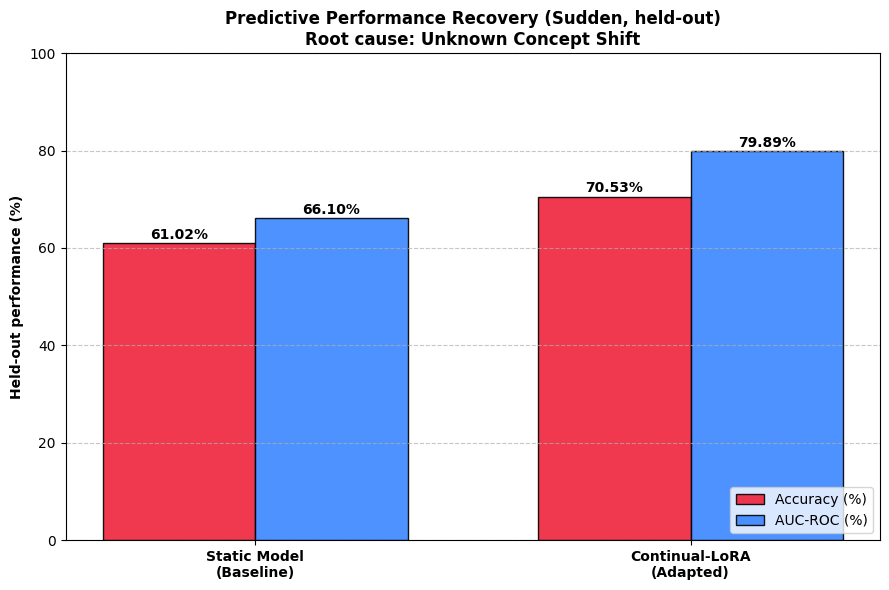

 HELD-OUT VALIDATION: ADAPTATION VELOCITY
 ✅ AUC-ROC gain +13.79 points after 8 epochs on unseen learners.


In [ ]:
import matplotlib.pyplot as plt
XT, YT, UT = EV[EVSETS[topology]["T"]]
pb, tb, _ = predict(model, XT, YT, UT)            # frozen W_0
pa, _, _  = predict(model_adapted, XT, YT, UT)    # adapter active
mb, ma = metrics(pb, tb), metrics(pa, tb)

print(f"\n📊 PREDICTIVE RECOVERY AUDIT ({topology.upper()} DRIFT, held-out learners, n={len(tb):,} interactions):")
print("\n--- A. CLASSIFICATION METRICS ---")
for k, lab in [("acc", "Accuracy"), ("auc", "AUC-ROC "), ("f1", "F1-Score")]:
    print(f"   {lab} Baseline : {mb[k]*100:.2f}%  | Adapted : {ma[k]*100:.2f}%  | Net Gain: {(ma[k]-mb[k])*100:+.2f}%")
print("\n--- B. ERROR METRICS ---")
print(f"   RMSE Baseline     : {mb['rmse']:.4f}   | Adapted : {ma['rmse']:.4f}   | Change: {ma['rmse']-mb['rmse']:+.4f}")

labels = ['Static Model\n(Baseline)', 'Continual-LoRA\n(Adapted)']
x = np.arange(2); w = 0.35; fig, ax = plt.subplots(figsize=(9, 6))
r1 = ax.bar(x - w/2, [mb['acc']*100, ma['acc']*100], w, label='Accuracy (%)', color='#ef233c', edgecolor='black', alpha=.9)
r2 = ax.bar(x + w/2, [mb['auc']*100, ma['auc']*100], w, label='AUC-ROC (%)', color='#3a86ff', edgecolor='black', alpha=.9)
ax.set_ylabel('Held-out performance (%)', fontweight='bold'); ax.set_ylim(0, 100); ax.set_xticks(x); ax.set_xticklabels(labels, fontweight='bold')
ax.set_title(f'Predictive Performance Recovery ({topology.capitalize()}, held-out)\nRoot cause: {root_cause}', fontweight='bold'); ax.legend(loc='lower right')
for rect in list(r1) + list(r2):
    ax.annotate(f'{rect.get_height():.2f}%', (rect.get_x() + rect.get_width()/2, rect.get_height()), xytext=(0, 3), textcoords="offset points", ha='center', fontweight='bold')
plt.grid(axis='y', linestyle='--', alpha=.7); plt.tight_layout(); plt.show()

print("=" * 60); print(" HELD-OUT VALIDATION: ADAPTATION VELOCITY"); print("=" * 60)
if (ma['auc'] - mb['auc']) > 0.10:
    print(f" ✅ AUC-ROC gain {100*(ma['auc']-mb['auc']):+.2f} points after {rt['epochs']} epochs on unseen learners.")
else:
    print(" ⚠️ AUC gain below the 0.10 operational threshold on held-out learners.")
print("=" * 60)

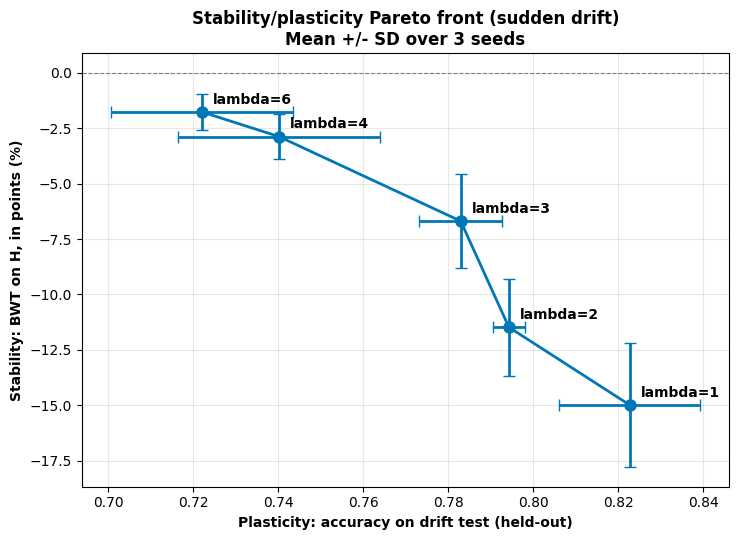


Pareto table:
 lambda_ret  acc_T  acc_T_sd  bwt_acc  bwt_acc_sd
        1.0 0.8227    0.0165 -14.9850      2.8029
        2.0 0.7943    0.0038 -11.4801      2.1904
        3.0 0.7830    0.0098  -6.6898      2.1136
        4.0 0.7402    0.0239  -2.8753      1.0281
        6.0 0.7221    0.0214  -1.7682      0.8307

Pick the lambda that maximises Acc_T while keeping BWT above the target (e.g. -5 pts).


In [ ]:
# ================================================================================================
# PARETO SWEEP: stability (BWT) vs plasticity (Acc_T) as a function of lambda_ret.
# Run after Section 7. Duration: ~10-15 min on T4 with 3 seeds.
# ================================================================================================
import matplotlib.pyplot as plt

LAMBDAS = [1.0, 2.0, 3.0, 4.0, 6.0]     # new range centred on H_retain dynamics
SWEEP_SEEDS = [42, 100, 2026]

sweep_rows = []
X_retain, Y_retain = make_retention_set(CFG["RETENTION"]["retention_split"], seed=42)
XvH, YvH, _ = EV["H"];             XvH, YvH = XvH[:300], YvH[:300]
XvT, YvT, _ = EV[EVSETS[topology]["T"]]; XvT, YvT = XvT[:300], YvT[:300]

for lam in LAMBDAS:
    for seed in SWEEP_SEEDS:
        set_seed(seed)
        m = make_lora(rt["r"], rt["alpha"]).to(DEV)
        fit_with_retention(
            m, BASE, Xa, Ya,
            epochs=rt["epochs"], lr=rt["lr_eff"], seed=seed,
            X_retain=X_retain, Y_retain=Y_retain,
            lambda_ret=lam, temperature=2.0, batch_ret=32,
            early_stop=False,           # disable early stopping to isolate the effect of lambda
            verbose=False,
        )
        pH, tH, _ = predict(m, *EV["H"])
        pT, tT, _ = predict(m, *EV[EVSETS[topology]["T"]])
        mH, mT = metrics(pH, tH), metrics(pT, tT)
        p0, t0, _ = predict(BASE, *EV["H"]); m0 = metrics(p0, t0)
        sweep_rows.append(dict(
            lambda_ret=lam, seed=seed,
            acc_T=mT["acc"], auc_T=mT["auc"],
            acc_H=mH["acc"], auc_H=mH["auc"],
            bwt_acc=(mH["acc"] - m0["acc"]) * 100,
            bwt_auc=(mH["auc"] - m0["auc"]) * 100,
        ))
        del m

import pandas as pd
SWEEP = pd.DataFrame(sweep_rows)
SWEEP.to_csv(CFG["OUT_DIR"] + f"pareto_sweep_{topology}.csv", index=False)

agg = SWEEP.groupby("lambda_ret").agg(
    acc_T=("acc_T", "mean"), acc_T_sd=("acc_T", "std"),
    bwt_acc=("bwt_acc", "mean"), bwt_acc_sd=("bwt_acc", "std"),
).reset_index()

fig, ax = plt.subplots(figsize=(7.5, 5.5))
ax.errorbar(agg.acc_T, agg.bwt_acc,
            xerr=agg.acc_T_sd, yerr=agg.bwt_acc_sd,
            fmt="o-", capsize=4, color="#0077b6", lw=2, ms=8)
for _, r in agg.iterrows():
    ax.annotate(f"lambda={r.lambda_ret:g}", (r.acc_T, r.bwt_acc),
                textcoords="offset points", xytext=(8, 6), fontsize=10, fontweight="bold")
ax.axhline(0, color="grey", ls="--", lw=0.8)
ax.set_xlabel("Plasticity: accuracy on drift test (held-out)", fontweight="bold")
ax.set_ylabel("Stability: BWT on H, in points (%)", fontweight="bold")
ax.set_title(f"Stability/plasticity Pareto front ({topology} drift)\nMean +/- SD over {len(SWEEP_SEEDS)} seeds",
             fontweight="bold")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(CFG["OUT_DIR"] + f"pareto_{topology}.png", dpi=200)
plt.savefig(CFG["OUT_DIR"] + f"pareto_{topology}.pdf")
plt.show()

print("\nPareto table:")
print(agg.round(4).to_string(index=False))
print("\nPick the lambda that maximises Acc_T while keeping BWT above the target (e.g. -5 pts).")

## Section 8: Pilot Deployment Statistics (Ecological Validity)

In [ ]:
# =====================================================
# 1. LIVE PILOT STATISTICS, COMPUTED FROM SUPABASE (not typed)
#    tables: xCARE_Alerts (JSON drift payloads) and xGATES (learner reactions)
# =====================================================
import json, os, numpy as np, pandas as pd
os.system("pip -q install supabase")

def _payload(x):
    if isinstance(x, str):
        try: return json.loads(x)
        except Exception: return {}
    return x or {}

def _first(d, keys):
    for k in keys:
        if isinstance(d, dict) and d.get(k) not in (None, ""): return d[k]
    return None

PILOT = {}
try:
    from supabase import create_client
    from google.colab import userdata
    sb = create_client(userdata.get("SUPABASE_URL"), userdata.get("SUPABASE_KEY"))

    def fetch(name, page=1000):
        rows, start = [], 0
        while True:
            r = sb.table(name).select("*").range(start, start + page - 1).execute().data
            rows += r
            if len(r) < page: break
            start += page
        return pd.DataFrame(rows)

    A = fetch("xCARE_Alerts"); G = fetch("xGATES")
    LIVE_DB = True
except Exception as e:
    print("⚠️ Supabase unavailable -> typed fallback values (NOT computed from the database):", repr(e)[:150])
    LIVE_DB = False

if LIVE_DB:
    P = A["payload"].map(_payload)
    def _g(d, *path):
        for k in path:
            if not isinstance(d, dict): return None
            d = d.get(k)
        return d
    def _first_of(d, paths):
        for pth in paths:
            v = _g(d, *pth)
            if v not in (None, ""): return v
        return None
    A["schema"]     = P.map(lambda d: "heuristic" if str(_g(d, "alert_metadata", "alert_id")).startswith("XG-HEURISTIC") else ("statistical" if _g(d, "statistical_analysis", "drift_type") else "other"))
    A["drift_type"] = P.map(lambda d: _first_of(d, [("statistical_analysis", "drift_type")]))
    A["severity"]   = P.map(lambda d: _first_of(d, [("statistical_analysis", "severity_score"), ("statistical_analysis", "severity_level")])).astype(float)
    A["root_cause"] = P.map(lambda d: _first_of(d, [("xai_metadata", "root_cause_feature"), ("xai_metadata", "root_cause")]))
    A["learner"]    = P.map(lambda d: _first_of(d, [("xai_metadata", "affected_user_id"), ("alert_metadata", "affected_user_id")]))
    A["subject"]    = P.map(lambda d: _first_of(d, [("xai_metadata", "subject")]))
    A["skill"]      = P.map(lambda d: _first_of(d, [("alert_metadata", "skill_id"), ("xai_metadata", "skill_id"), ("xai_metadata", "affected_skill")]))
    A["t"] = pd.to_datetime(A.get("created_at"), errors="coerce")
    uc = next((c for c in ["user_id", "student_id", "learner_id", "username", "pseudonym"] if c in G.columns), None)

    PILOT = dict(
        n_alert_rows=int(len(A)),
        n_learners_with_alert=int(A["learner"].nunique()),
        drift_type_counts=A["drift_type"].value_counts(dropna=False).to_dict(),
        severity=dict(n_distinct=int(A["severity"].nunique()), min=float(A["severity"].min()), median=float(A["severity"].median()), max=float(A["severity"].max())),
        root_cause_counts=A["root_cause"].value_counts(dropna=False).to_dict(),
        skill_counts=A["skill"].astype(str).value_counts(dropna=False).to_dict(),
        schema_counts=A["schema"].value_counts().to_dict(),
        subject_counts=A["subject"].astype(str).value_counts().to_dict(),
        alerts_per_learner=A["learner"].astype(str).value_counts().to_dict(),
        period=[str(A["t"].min()), str(A["t"].max())],
        duplicates_same_learner_cause_severity=int(A.duplicated(subset=["learner", "root_cause", "severity"]).sum()),
        decision_counts=A["decision"].value_counts(dropna=False).to_dict() if "decision" in A.columns else None,
        xgates_rows=int(len(G)), xgates_columns=list(G.columns),
        xgates_learners=int(G[uc].nunique()) if uc else None,
    )
    ans = G[G["correct"].notna()] if "correct" in G.columns else G          # rows with correct = NULL are session-start events
    PILOT.update(
        xgates_answered_rows=int(len(ans)),
        xgates_answered_learners=int(ans[uc].nunique()) if uc else None,
        xgates_skill_counts=ans["skill_id"].astype(str).value_counts().to_dict() if "skill_id" in ans.columns else None,
        xgates_group_type_counts=G["group_type"].astype(str).value_counts().to_dict() if "group_type" in G.columns else None,
        xgates_period=[str(pd.to_datetime(G["created_at"], errors="coerce").min()), str(pd.to_datetime(G["created_at"], errors="coerce").max())] if "created_at" in G.columns else None,
    )
    Gs = G.assign(t=pd.to_datetime(G["created_at"], errors="coerce")).sort_values("t")
    As = Gs[Gs["correct"].notna()] if "correct" in Gs.columns else Gs
    PILOT["date_of_972nd_row"] = str(Gs.iloc[971]["t"]) if len(Gs) >= 972 else None          # find the cut-off of the earlier count
    PILOT["date_of_972nd_answered_row"] = str(As.iloc[971]["t"]) if len(As) >= 972 else None
    PILOT["answered_rows_per_user_top50"] = As.groupby(uc).size().sort_values(ascending=False).head(50).to_dict() if uc else None
    _un = A[A["drift_type"].isna()]["payload"]
    PILOT["sample_unparsed_payload"] = str(_un.iloc[0])[:400] if len(_un) else None
    _h = A[A["schema"] == "heuristic"]["payload"]
    PILOT["heuristic_payload_keys"] = {k: (list(v.keys()) if isinstance(v, dict) else None) for k, v in _payload(_h.iloc[0]).items()} if len(_h) else None
    print("=" * 65); print(" 📡 LIVE PILOT DEPLOYMENT SUMMARY (computed from Supabase)"); print("=" * 65)
    for k, v in PILOT.items(): print(f"   {k:<42}: {v}")
    print("=" * 65)
    if PILOT["severity"]["n_distinct"] <= 1:
        print(f" ⚠️ All alerts carry the same severity ({PILOT['severity']['max']}). Describe them as rule-triggered emergency flags")
        print("    (not as continuous statistical severities): Eq. (3) then reduces to a constant learning-rate multiplier.")
    if PILOT["n_alert_rows"] != 12:
        print(f" ⚠️ The manuscript reports 12 drift events; the table holds {PILOT['n_alert_rows']} rows "
              f"({PILOT['duplicates_same_learner_cause_severity']} duplicates by learner/cause/severity). Reconcile before submission.")
    json.dump(PILOT, open(CFG["OUT_DIR"] + "pilot_stats.json", "w"), indent=2, default=str)
else:
    COHORT_STATS = {  # typed fallback, transcribed from the earlier export
        'n_learners': 30, 'telemetry_records': 972, 'drift_events': 12,
        'skill_categories': ['Linear Equations', 'Algebra', 'Scatter Plot', 'Probability Compound', 'Venn Diagram'],
        'deployment_period': 'April-May 2026'}
    for k, v in COHORT_STATS.items(): print(f"   {k:<22}: {v}")

 📡 LIVE PILOT DEPLOYMENT SUMMARY (computed from Supabase)
   n_alert_rows                              : 25
   n_learners_with_alert                     : 4
   drift_type_counts                         : {'SUDDEN DRIFT': 13, None: 12}
   severity                                  : {'n_distinct': 1, 'min': 0.99, 'median': 0.99, 'max': 0.99}
   root_cause_counts                         : {'Pedagogical Emergency (Consecutive Errors)': 13, 'Pedagogical Emergency: Consecutive errors': 12}
   skill_counts                              : {'nan': 13, '101.0': 7, '102.0': 2, '106.0': 1, '104.0': 1, '105.0': 1}
   schema_counts                             : {'statistical': 13, 'heuristic': 12}
   subject_counts                            : {'None': 13, 'Linear Equations': 7, 'Algebra': 2, 'Scatter Plot': 1, 'Probability Compound': 1, 'Venn Diagram': 1}
   alerts_per_learner                        : {'184301': 12, '869829': 9, '307682': 3, '504173': 1}
   period                                    

## Section 9: Memory Sanctuary Audit and Backward Transfer (BWT)

**What is verified.** (i) *Reversibility*: with the adapter disabled, the adapted object reproduces the pristine $W_0$ output exactly.
(ii) *Functional retention*: BWT is the change in accuracy on the held-out pre-drift set **H** between the deployed model
(adapter **active**) and $W_0$. Freezing $W_0$ guarantees (i); it does not guarantee (ii), which is measured, not assumed.

🔍 Auditing Historical Memory Retention (held-out pre-drift set H)...
   Reversibility check  max|W0 - adapter_disabled| = 0.00e+00   -> OK
   Functional change    max|W0 - adapter_active|   = 0.646   (must be > 0 once the adapter is trained)

📊 RETENTION METRICS (held-out pre-drift set H, n=6,353):
   - W_0 historical accuracy       : 84.43%   (AUC 89.99%)
   - Adapted historical accuracy   : 83.46%   (AUC 88.55%)
   - Backward Transfer (accuracy)  : -0.98 points   (AUC: -1.44)

 MEMORY SANCTUARY AUDIT
 ✅ Reversible: disabling the adapter restores W_0 exactly.
 ⚠️ Functional forgetting with the adapter active (-0.98 points). Report it; see Sections 11-15 for baselines.


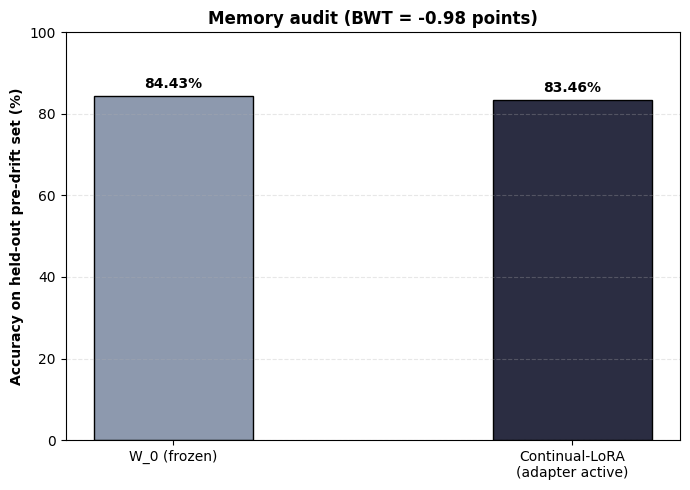

In [ ]:
print("🔍 Auditing Historical Memory Retention (held-out pre-drift set H)...")
assert_pristine(model)
Xh, Yh, Uh = EV["H"]

p0, t0, _ = predict(model, Xh, Yh, Uh)                          # frozen W_0 (pristine object)
with model_adapted.disable_adapter():
    p_dis, _, _ = predict(model_adapted, Xh, Yh, Uh)            # adapter disabled
p1, _, _ = predict(model_adapted, Xh, Yh, Uh)                   # deployed model (adapter active)

rev = float(np.abs(p0 - p_dis).max())
print(f"   Reversibility check  max|W0 - adapter_disabled| = {rev:.2e}   ->", "OK" if rev < 1e-5 else "FAILED")
assert rev < 1e-5, "adapter-disabled output differs from W_0"
print(f"   Functional change    max|W0 - adapter_active|   = {float(np.abs(p0 - p1).max()):.3f}   (must be > 0 once the adapter is trained)")

m0, m1 = metrics(p0, t0), metrics(p1, t0)
bwt_acc, bwt_auc = (m1['acc'] - m0['acc']) * 100, (m1['auc'] - m0['auc']) * 100
print(f"\n📊 RETENTION METRICS (held-out pre-drift set H, n={len(t0):,}):")
print(f"   - W_0 historical accuracy       : {m0['acc']*100:.2f}%   (AUC {m0['auc']*100:.2f}%)")
print(f"   - Adapted historical accuracy   : {m1['acc']*100:.2f}%   (AUC {m1['auc']*100:.2f}%)")
print(f"   - Backward Transfer (accuracy)  : {bwt_acc:+.2f} points   (AUC: {bwt_auc:+.2f})")
print("\n" + "=" * 65); print(" MEMORY SANCTUARY AUDIT"); print("=" * 65)
print(" ✅ Reversible: disabling the adapter restores W_0 exactly.")
if bwt_acc >= 0: print(" ✅ No loss of pre-drift accuracy with the adapter active.")
else: print(f" ⚠️ Functional forgetting with the adapter active ({bwt_acc:+.2f} points). Report it; see Sections 11-15 for baselines.")
print("=" * 65)

plt.figure(figsize=(7, 5))
bars = plt.bar(['W_0 (frozen)', 'Continual-LoRA\n(adapter active)'], [m0['acc']*100, m1['acc']*100], color=['#8d99ae', '#2b2d42'], edgecolor='black', width=.4)
plt.ylabel('Accuracy on held-out pre-drift set (%)', fontweight='bold'); plt.ylim(0, 100); plt.title(f'Memory audit (BWT = {bwt_acc:+.2f} points)', fontweight='bold')
for b in bars: plt.text(b.get_x() + b.get_width()/2, b.get_height() + 2, f'{b.get_height():.2f}%', ha='center', fontweight='bold')
plt.grid(axis='y', linestyle='--', alpha=.3); plt.tight_layout(); plt.show()

## Section 10: Formative Expert Evaluation (TAM & SUS)

In [ ]:
# =====================================================
# 1. FORMATIVE EVALUATION PROCESSING (TAM & SUS)
# Part A: item-level statistics from the Google Form summary (counts copied from the form's response summary)
# Part B: respondent-level statistics from the exported individual responses (CSV), if available
# =====================================================
import glob, numpy as np, pandas as pd
from scipy import stats

# --- Part A: response counts per item (N = 5), from the form summary ---
FORM_COUNTS = {
    # SUS (standard numbering; NOTE the form lists the items in the order Q1..Q7, Q9, Q8, Q10)
    "Q1": {2: 1, 4: 1, 5: 3}, "Q2": {1: 4, 2: 1}, "Q3": {5: 5}, "Q4": {1: 4, 5: 1}, "Q5": {4: 4, 5: 1},
    "Q6": {1: 5}, "Q7": {4: 2, 5: 3}, "Q8": {1: 5}, "Q9": {4: 1, 5: 4}, "Q10": {1: 5},
    # TAM
    "PU1": {4: 1, 5: 4}, "PU2": {3: 1, 5: 4}, "PU3": {4: 2, 5: 3}, "PU4": {4: 3, 5: 2}, "PU5": {4: 2, 5: 3},
    "PE1": {1: 1, 3: 1, 4: 2, 5: 1}, "PE2": {1: 1, 4: 2, 5: 2}, "PE3": {3: 1, 4: 1, 5: 3}, "PE4": {4: 2, 5: 3}, "PE5": {4: 1, 5: 4},
}
def expand(c): return np.array([k for k, n in c.items() for _ in range(n)], float)
def ci95(a):
    if len(a) < 2 or a.std(ddof=1) == 0: return (a.mean(), a.mean())
    lo, hi = stats.t.interval(0.95, df=len(a) - 1, loc=a.mean(), scale=stats.sem(a)); return (max(1, lo), min(5, hi))

print("--- A. TAM items (from the form summary) ---")
for k in [f"PU{i}" for i in range(1, 6)] + [f"PE{i}" for i in range(1, 6)]:
    a = expand(FORM_COUNTS[k]); lo, hi = ci95(a)
    print(f"   {k}: Mean={a.mean():.2f}, SD={a.std(ddof=1):.2f}, 95% CI=[{lo:.2f}, {hi:.2f}]")
pu = np.mean([expand(FORM_COUNTS[f"PU{i}"]).mean() for i in range(1, 6)]); pe = np.mean([expand(FORM_COUNTS[f"PE{i}"]).mean() for i in range(1, 6)])
print(f"   Mean PU = {pu:.2f} | Mean PEOU = {pe:.2f}")
neg = {"Q2", "Q4", "Q6", "Q8", "Q10"}
contrib = [(5 - expand(FORM_COUNTS[q]).mean()) if q in neg else (expand(FORM_COUNTS[q]).mean() - 1) for q in [f"Q{i}" for i in range(1, 11)]]
print(f"   SUS mean implied by the item distributions = {sum(contrib) * 2.5:.2f}  (the SD needs the individual rows, see Part B)")

# --- Part B: individual responses (Google Sheets export). Columns follow the FORM order ---
FORM_ORDER = ["Q1", "Q2", "Q3", "Q4", "Q5", "Q6", "Q7", "Q9", "Q8", "Q10", "PU1", "PU2", "PU3", "PU4", "PU5", "PE1", "PE2", "PE3", "PE4", "PE5"]
def _is_form_export(p):
    """The Google Forms export is recognised by its content (a column starting with '(PU1)'), not by its file name."""
    try: return any(str(c).strip().startswith("(PU1)") for c in pd.read_csv(p, nrows=0).columns)
    except Exception: return False
cands = [p for p in glob.glob(CFG["DRIVE_DIR"] + "*.csv") + glob.glob(CFG["DRIVE_DIR"] + "**/*.csv", recursive=True) if _is_form_export(p)]
if not cands:
    print("\nℹ️ Part B skipped: export the form responses (Google Sheets > File > Download > CSV) into the data folder,"
          "\n   (any file name), to compute respondent-level SDs and the SUS SD.")
else:
    D_ = pd.read_csv(cands[0])
    D_ = D_.drop(columns=[c for c in D_.columns if str(c).strip().lower() in ("score", "horodateur", "timestamp")])   # Google Forms adds a Score column
    num = D_.select_dtypes(include=[np.number])
    assert num.shape[1] == 20, f"expected 20 numeric answer columns, found {num.shape[1]} in {cands[0]}"
    num.columns = FORM_ORDER
    print(f"\n--- B. Individual responses: {os.path.basename(cands[0])} (n={len(num)}) ---")
    for g_, items in [("PU", [f"PU{i}" for i in range(1, 6)]), ("PEOU", [f"PE{i}" for i in range(1, 6)])]:
        r_ = num[items].mean(axis=1).values; lo, hi = ci95(r_)
        print(f"   {g_}: mean {r_.mean():.2f}, SD {r_.std(ddof=1):.2f}, 95% CI [{lo:.2f}, {hi:.2f}] (respondent-level)")
    def sus_row(r):
        return (sum(r[f"Q{i}"] - 1 for i in (1, 3, 5, 7, 9)) + sum(5 - r[f"Q{i}"] for i in (2, 4, 6, 8, 10))) * 2.5
    s_ = num.apply(sus_row, axis=1).values
    print(f"   SUS per respondent: {s_} | mean {s_.mean():.2f}, SD {s_.std(ddof=1):.2f}")

--- A. TAM items (from the form summary) ---
   PU1: Mean=4.80, SD=0.45, 95% CI=[4.24, 5.00]
   PU2: Mean=4.60, SD=0.89, 95% CI=[3.49, 5.00]
   PU3: Mean=4.60, SD=0.55, 95% CI=[3.92, 5.00]
   PU4: Mean=4.40, SD=0.55, 95% CI=[3.72, 5.00]
   PU5: Mean=4.60, SD=0.55, 95% CI=[3.92, 5.00]
   PE1: Mean=3.40, SD=1.52, 95% CI=[1.52, 5.00]
   PE2: Mean=3.80, SD=1.64, 95% CI=[1.76, 5.00]
   PE3: Mean=4.40, SD=0.89, 95% CI=[3.29, 5.00]
   PE4: Mean=4.60, SD=0.55, 95% CI=[3.92, 5.00]
   PE5: Mean=4.80, SD=0.45, 95% CI=[4.24, 5.00]
   Mean PU = 4.60 | Mean PEOU = 4.20
   SUS mean implied by the item distributions = 92.00  (the SD needs the individual rows, see Part B)

ℹ️ Part B skipped: export the form responses (Google Sheets > File > Download > CSV) into the data folder,
   (any file name), to compute respondent-level SDs and the SUS SD.


## Sections 11–15: Statistical evaluation over 15 seeds (held-out)

All experiments call `route()` and the same training function as Sections 5–6.
* **E1** — dynamic router vs static $r{=}16$ on each topology, same epochs and learning rate (only $r,\alpha$ differ).
* **E2** — rank × topology grid under one common budget (computed heat-map).
* **E3** — continual-learning baselines on sudden drift: FFT (matched budget and the 15-epoch protocol), FFT+EWC, FFT+replay, LoRA+replay.
* **E4** — mixed pre/post-drift stream: always-on adapter vs context-gated adapter (oracle gate).

In [ ]:
# ================================================================================================
# SECTIONS 11-15 — RESILIENT RUN
# Auto-checkpoints ROWS and PRED to disk after every run() call.
# If the session is interrupted, rerun the cell: completed configurations are skipped.
# ================================================================================================
import pickle, os, time

ROWS, PRED = [], {}
CKPT_ROWS = CFG["OUT_DIR"] + "results_long.csv"
CKPT_PRED = CFG["OUT_DIR"] + "predictions.pkl"
DONE = set()

# --- 1. Resume: load previous partial results if any ---
if os.path.exists(CKPT_ROWS):
    try:
        _prev = pd.read_csv(CKPT_ROWS)
        ROWS = _prev.to_dict("records")
        DONE = {(r["exp"], r["topology"], r["method"], int(r["seed"]), r["evalset"]) for r in ROWS}
        print(f"[Resume] Loaded {len(ROWS)} rows from checkpoint.")

        # ALSO restore the raw predictions (needed by the bootstrap downstream)
        if os.path.exists(CKPT_PRED):
            with open(CKPT_PRED, "rb") as f:
                _saved = pickle.load(f)
            PRED.update(_saved.get("PRED", {}))
            print(f"[Resume] Reloaded {len(PRED)} raw predictions from predictions.pkl.")
    except Exception as e:
        print(f"[Resume] Could not read checkpoint ({e}); starting fresh.")

def _already_done(exp, topo, method, seed, evalset):
    return (exp, topo, method, int(seed), evalset) in DONE

def _checkpoint():
    """Persist ROWS and PRED to disk (atomic write via temp file)."""
    df = pd.DataFrame(ROWS).drop_duplicates(["exp", "topology", "method", "seed", "evalset"], keep="last")
    df.to_csv(CKPT_ROWS + ".tmp", index=False)
    os.replace(CKPT_ROWS + ".tmp", CKPT_ROWS)

    # Protect PRED from being overwritten by an empty dictionary
    if len(PRED) > 0:
        with open(CKPT_PRED + ".tmp", "wb") as f:
            pickle.dump(dict(PRED=PRED, LABEL=LABEL, GROUP=GROUP, BASE_P=BASE_P), f)
        os.replace(CKPT_PRED + ".tmp", CKPT_PRED)

def rec(exp, topo, method, seed, ev, p, ntr):
    key = (exp, topo, method, int(seed), ev)
    if key in DONE:
        return
    PRED[key] = p
    ROWS.append(dict(exp=exp, topology=topo, method=method, seed=seed, evalset=ev,
                     n_trainable=ntr, **metrics(p, LABEL[EVSETS[topo][ev]])))
    DONE.add(key)

def eval_model(exp, topo, method, seed, model, ntr):
    for ev, key in EVSETS[topo].items():
        if _already_done(exp, topo, method, seed, ev):
            continue
        rec(exp, topo, method, seed, ev, predict(model, *EV[key])[0], ntr)

def fisher():
    X_, Y_, _ = BLK["TRAIN"]; k = torch.randperm(len(X_))[:min(512, len(X_))]
    m = copy.deepcopy(BASE); [p.requires_grad_(True) for p in m.parameters()]
    F_ = {n_: torch.zeros_like(p) for n_, p in m.named_parameters()}; nb = 0
    for i in range(0, len(k), CFG["BATCH"]):
        m.zero_grad(); b = k[i:i + CFG["BATCH"]]; crit(m(X_[b].to(DEV)), Y_[b].to(DEV)).backward(); nb += 1
        for n_, p in m.named_parameters(): F_[n_] += p.grad.detach() ** 2
    return {n_: v / nb for n_, v in F_.items()}, {n_: p.detach().clone() for n_, p in BASE.named_parameters()}

def replay_buf():
    X_, Y_, _ = BLK["TRAIN"]; k = torch.randperm(len(X_), generator=torch.Generator().manual_seed(0))[:max(8, int(CFG["REPLAY_FRAC"] * len(X_)))]
    return X_[k].cpu(), Y_[k].cpu()

TIMES = {}
_RET_CACHE = {}
def _get_retention():
    key = CFG["RETENTION"]["retention_split"]
    if key not in _RET_CACHE:
        _RET_CACHE[key] = make_retention_set(key, seed=CFG["MASTER_SEED"])
    return _RET_CACHE[key]

# W0 baseline accuracy on H (used by the asymmetric penalty)
with torch.no_grad():
    _Xh0, _Yh0, _Uh0 = EV["H"]
    _p0h, _t0h, _ = predict(BASE, _Xh0[:500], _Yh0[:500], _Uh0[:500])
    BASELINE_H_ACC = float(((_p0h > 0.5) == (_t0h > 0.5)).mean())

def run(exp, topo, method, spec, seed):
    # Skip if all eval sets already computed for this key
    if all(_already_done(exp, topo, method, seed, ev) for ev in EVSETS[topo]):
        return
    _ts = time.time(); set_seed(seed); Xa, Ya, _ = ADAPT[topo]
    if spec["kind"] == "lora":
        m = make_lora(spec["r"], spec["alpha"])
    else:
        m = copy.deepcopy(BASE); [p.requires_grad_(True) for p in m.parameters()]
    m = m.to(DEV)

    RET = CFG["RETENTION"]
    Xr_, Yr_ = (None, None)
    if RET["use_retention"] and spec.get("retention", True) and spec["kind"] == "lora":
        Xr_, Yr_ = _get_retention()

    replay_source = BLK["H_retain"] if RET["retention_split"] == "H_RETAIN" else BLK["TRAIN"]
    rep_ = spec.get("replay")
    if rep_ is None and RET["replay_frac_h"] > 0 and spec.get("strat_replay", True):
        rep_ = make_stratified_replay(replay_source, frac=RET["replay_frac_h"], seed=seed)

    if Xr_ is not None or rep_ is not None:
        fit_with_retention(
            m, BASE, Xa, Ya,
            epochs=spec["epochs"], lr=spec["lr"], seed=seed,
            X_retain=Xr_, Y_retain=Yr_,
            lambda_ret=RET["lambda_ret"] if Xr_ is not None else 0.0,
            temperature=RET["temperature"], batch_ret=RET["batch_ret"],
            replay=rep_, ewc=spec.get("ewc"),
            early_stop=False, baseline_H=BASELINE_H_ACC, verbose=False,
        )
    else:
        fit(m, Xa, Ya, spec["epochs"], spec["lr"], seed,
            ewc=spec.get("ewc"), replay=spec.get("replay"))

    TIMES[(exp, topo, method, seed)] = time.time() - _ts
    eval_model(exp, topo, method, seed, m, n_trainable(m)); del m
    _checkpoint()

# -- base model rows (deterministic -> seed = -1) --
for topo in EVSETS:
    for ev, key in EVSETS[topo].items():
        if not _already_done("main", topo, "base", -1, ev):
            rec("main", topo, "base", -1, ev, BASE_P[key], 0)
_checkpoint()

t0 = time.time()

# E1: budget-matched dynamic router vs static r=16 on every topology
for topo in ["sudden", "gradual", "recurring"]:
    rt_ = route(topo); print(f"{topo} -> {rt_} | elapsed {time.time()-t0:.0f}s")
    for seed in CFG["SEEDS"]:
        run("main", topo, "xcare", dict(kind="lora", r=rt_["r"], alpha=rt_["alpha"], epochs=rt_["epochs"], lr=rt_["lr_eff"]), seed)
        if topo != "sudden":
            run("main", topo, "static16", dict(kind="lora", r=16, alpha=64, epochs=rt_["epochs"], lr=rt_["lr_eff"]), seed)
    if topo == "sudden":
        for (e, t, m_, s_, ev), p in list(PRED.items()):
            if (e, t, m_) == ("main", "sudden", "xcare"):
                PRED[(e, t, "static16", s_, ev)] = p
        for r_ in [x for x in ROWS if x["topology"] == "sudden" and x["method"] == "xcare"]:
            ROWS.append({**r_, "method": "static16"})
        _checkpoint()
    print(f"  done {topo} ({time.time() - t0:.0f}s)")

# E2: rank x topology grid
for topo in ["sudden", "gradual", "recurring"]:
    for r_ in CFG["GRID_RANKS"]:
        for seed in CFG["SEEDS"]:
            run("grid", topo, f"r{r_}", dict(kind="lora", r=r_, alpha=4 * r_, epochs=CFG["GRID_EPOCHS"], lr=CFG["GRID_LR"]), seed)
    print(f"  grid {topo} done ({time.time() - t0:.0f}s)")

# E3: continual-learning baselines
rs = route("sudden"); fisher_state, rbuf = fisher(), replay_buf()
specs = {
    "fft_matched": dict(kind="fft", epochs=rs["epochs"], lr=rs["lr_eff"]),
    "fft_paper":   dict(kind="fft", epochs=CFG["FFT_PAPER"]["epochs"], lr=CFG["FFT_PAPER"]["lr"]),
    "fft_ewc":     dict(kind="fft", epochs=rs["epochs"], lr=rs["lr_eff"], ewc=fisher_state),
    "fft_replay":  dict(kind="fft", epochs=rs["epochs"], lr=rs["lr_eff"], replay=rbuf),
    "lora_replay": dict(kind="lora", r=rs["r"], alpha=rs["alpha"], epochs=rs["epochs"], lr=rs["lr_eff"], replay=rbuf),
}
for name, sp in specs.items():
    for seed in CFG["SEEDS"]:
        run("cl", "sudden", name, sp, seed)
    print(f"  cl {name} done ({time.time() - t0:.0f}s)")

# E4: mixed stream
def mixed(topo, method, seed, gate):
    pH = PRED[("main" if method in ("xcare", "static16") else "cl", topo, method, seed, "H")]
    pT = PRED[("main" if method in ("xcare", "static16") else "cl", topo, method, seed, "T")]
    pH = BASE_P["H"] if gate else pH
    return np.r_[pH, pT], np.r_[LABEL["H"], LABEL[EVSETS[topo]["T"]]]

for method in ["xcare", "fft_matched", "lora_replay"]:
    for seed in CFG["SEEDS"]:
        for gate in (False, True):
            key = ("mix", "sudden", f"{'gated' if gate else 'always'}:{method}", int(seed), "MIX")
            if key in DONE: continue
            p, t = mixed("sudden", method, seed, gate)
            ROWS.append(dict(exp="mix", topology="sudden", method=key[2], seed=seed,
                             evalset="MIX", n_trainable=0, **metrics(p, t)))
            DONE.add(key)
_checkpoint()

# Final consolidation
R = pd.DataFrame(ROWS).drop_duplicates(["exp", "topology", "method", "seed", "evalset"], keep="last")
R["train_s"] = [TIMES.get((r.exp, r.topology, r.method, r.seed), np.nan) for r in R.itertuples()]
R.to_csv(CKPT_ROWS, index=False)
with open(CKPT_PRED, "wb") as f:
    pickle.dump(dict(PRED=PRED, LABEL=LABEL, GROUP=GROUP, BASE_P=BASE_P), f)
print(R.groupby(["exp", "topology", "method", "evalset"]).size().head(40))
print(f"Total wall-clock this session: {time.time() - t0:.0f}s | Total rows: {len(R)}")

[Resume] Loaded 849 rows from checkpoint.
[Resume] Reloaded 218 raw predictions from predictions.pkl.
sudden -> {'r': 16, 'alpha': 64, 'epochs': 8, 'base_lr': 0.002, 'severity': 0.8177, 'lr_eff': 0.0036354, 'dropout': 0.1} | elapsed 0s
  done sudden (0s)
gradual -> {'r': 8, 'alpha': 32, 'epochs': 5, 'base_lr': 0.001, 'severity': 0.5, 'lr_eff': 0.0015, 'dropout': 0.1} | elapsed 0s
  done gradual (0s)
recurring -> {'r': 4, 'alpha': 16, 'epochs': 3, 'base_lr': 0.0005, 'severity': 0.5, 'lr_eff': 0.00075, 'dropout': 0.1} | elapsed 0s
  done recurring (0s)
  grid sudden done (0s)
  grid gradual done (0s)
  grid recurring done (0s)
  cl fft_matched done (1s)
  cl fft_paper done (1s)
  cl fft_ewc done (1s)
  cl fft_replay done (1s)
  cl lora_replay done (1s)
exp   topology   method       evalset
cl    sudden     fft_ewc      H          15
                              T          15
                 fft_matched  H          15
                              T          15
                 fft_pape

In [ ]:
# ================================================================================================
# PREDICTION RECOVERY
# Re-trains only the models needed for the cluster bootstrap and re-populates predictions.pkl.
# ================================================================================================
import pickle, os

# 1. Rebuild LABEL, GROUP, BASE_P (deterministic from BASE model)
LABEL, GROUP, BASE_P = {}, {}, {}
for k, (X_, Y_, U_) in EV.items():
    p_, t_, g_ = predict(BASE, X_, Y_, U_)
    BASE_P[k], LABEL[k], GROUP[k] = p_, t_, g_

# 2. Load whatever partial PRED survives (may be empty)
PRED = {}
if os.path.exists(CFG["OUT_DIR"] + "predictions.pkl"):
    try:
        with open(CFG["OUT_DIR"] + "predictions.pkl", "rb") as f:
            _saved = pickle.load(f)
        PRED = _saved.get("PRED", {}) or {}
        print(f"[Recovery] Loaded {len(PRED)} existing predictions.")
    except Exception as e:
        print(f"[Recovery] Could not load predictions.pkl: {e}")

# 3. Inject base predictions (deterministic -> seed = -1)
for topo in EVSETS:
    for ev, key in EVSETS[topo].items():
        PRED[("main", topo, "base", -1, ev)] = BASE_P[key]

# 4. Identify missing configurations (only what the bootstrap needs)
missing = []
for topo in ["sudden", "gradual", "recurring"]:
    methods = ["xcare"] if topo == "sudden" else ["xcare", "static16"]
    for method in methods:
        for seed in CFG["SEEDS"]:
            for ev in EVSETS[topo].keys():
                k = ("main", topo, method, seed, ev)
                if k not in PRED:
                    missing.append((topo, method, seed))
# Deduplicate (per seed, per topology, per method)
missing = list(set(missing))
print(f"[Recovery] {len(missing)} configurations to regenerate (approx. {len(missing)*50/60:.0f} min on T4).")

# 5. Compute W0 baseline accuracy on H (used by asymmetric penalty)
with torch.no_grad():
    _Xh0, _Yh0, _Uh0 = EV["H"]
    _p0h, _t0h, _ = predict(BASE, _Xh0[:500], _Yh0[:500], _Uh0[:500])
    BASELINE_H_ACC = float(((_p0h > 0.5) == (_t0h > 0.5)).mean())

# Retention set cache
_RET_CACHE = {}
def _get_retention():
    key = CFG["RETENTION"]["retention_split"]
    if key not in _RET_CACHE:
        _RET_CACHE[key] = make_retention_set(key, seed=CFG["MASTER_SEED"])
    return _RET_CACHE[key]

# 6. Regenerate missing configurations
import time
_t_start = time.time()
for i, (topo, method, seed) in enumerate(missing, 1):
    print(f"[{i}/{len(missing)}] Regenerating {topo} | {method} | seed={seed} | elapsed {time.time()-_t_start:.0f}s")
    rt_ = route(topo)
    spec = dict(kind="lora",
                r=rt_["r"] if method == "xcare" else 16,
                alpha=rt_["alpha"] if method == "xcare" else 64,
                epochs=rt_["epochs"],
                lr=rt_["lr_eff"])

    set_seed(seed)
    Xa, Ya, _ = ADAPT[topo]
    m = make_lora(spec["r"], spec["alpha"]).to(DEV)

    RET = CFG["RETENTION"]
    Xr_, Yr_ = _get_retention()
    replay_source = BLK["H_retain"] if RET["retention_split"] == "H_RETAIN" else BLK["TRAIN"]
    rep_ = make_stratified_replay(replay_source, frac=RET["replay_frac_h"], seed=seed)

    fit_with_retention(
        m, BASE, Xa, Ya,
        epochs=spec["epochs"], lr=spec["lr"], seed=seed,
        X_retain=Xr_, Y_retain=Yr_,
        lambda_ret=RET["lambda_ret"], temperature=RET["temperature"],
        batch_ret=RET["batch_ret"], replay=rep_,
        early_stop=False, baseline_H=BASELINE_H_ACC, verbose=False,
    )

    # Extract predictions for each eval set
    for ev, key in EVSETS[topo].items():
        p, t, g = predict(m, *EV[key])
        PRED[("main", topo, method, seed, ev)] = p

    del m
    torch.cuda.empty_cache()

# 7. Save the recovered predictions (only if non-empty)
if len(PRED) > 0:
    tmp = CFG["OUT_DIR"] + "predictions.pkl.tmp"
    with open(tmp, "wb") as f:
        pickle.dump(dict(PRED=PRED, LABEL=LABEL, GROUP=GROUP, BASE_P=BASE_P), f)
    os.replace(tmp, CFG["OUT_DIR"] + "predictions.pkl")
    print(f"\n✅ Recovery complete: {len(PRED)} predictions saved to predictions.pkl")
else:
    print("\n❌ Recovery failed: PRED is still empty.")

[Recovery] Loaded 0 existing predictions.
[Recovery] 75 configurations to regenerate (approx. 62 min on T4).
[1/75] Regenerating gradual | static16 | seed=100 | elapsed 0s
[2/75] Regenerating gradual | xcare | seed=8888 | elapsed 32s
[3/75] Regenerating recurring | xcare | seed=8888 | elapsed 64s
[4/75] Regenerating recurring | static16 | seed=100 | elapsed 91s
[5/75] Regenerating recurring | xcare | seed=666 | elapsed 119s
[6/75] Regenerating recurring | static16 | seed=42 | elapsed 148s
[7/75] Regenerating recurring | static16 | seed=222 | elapsed 176s
[8/75] Regenerating gradual | static16 | seed=777 | elapsed 203s
[9/75] Regenerating recurring | static16 | seed=777 | elapsed 235s
[10/75] Regenerating gradual | xcare | seed=333 | elapsed 263s
[11/75] Regenerating sudden | xcare | seed=555 | elapsed 295s
[12/75] Regenerating recurring | xcare | seed=333 | elapsed 346s
[13/75] Regenerating gradual | xcare | seed=7777 | elapsed 374s
[14/75] Regenerating recurring | xcare | seed=7777 | 

### Statistics: BWT, exact Wilcoxon, paired $d_z$, Holm, learner-level cluster bootstrap

In [ ]:
base_H = R[(R.method == "base") & (R.evalset == "H")].iloc[0]
H = R[(R.evalset == "H") & (R.method != "base")].copy()
H["bwt_acc"] = H.acc - base_H.acc; H["bwt_auc"] = H.auc - base_H.auc
BWT = H[["exp", "topology", "method", "seed", "bwt_acc", "bwt_auc"]]

def vec(df_, **flt):
    q = df_
    for k, v in flt.items(): q = q[q[k] == v]
    return q.sort_values("seed")

def paired(a, b, label=""):
    a, b = np.asarray(a, float), np.asarray(b, float); d = a - b
    try: p = stats.wilcoxon(a, b, method="exact").pvalue if np.any(d != 0) else 1.0
    except ValueError: p = 1.0
    sd = d.std(ddof=1) if len(d) > 1 else np.nan
    return dict(cmp=label, mean_diff=float(d.mean()), sd_diff=float(sd), p_exact=float(p),
                dz=float(d.mean() / sd) if sd and sd > 0 else np.nan, n=len(d))

def holm(ps):
    ps = np.asarray(ps); o = np.argsort(ps); m = len(ps); adj = np.empty(m); run_max = 0
    for rank, i in enumerate(o):
        run_max = max(run_max, (m - rank) * ps[i]); adj[i] = min(1.0, run_max)
    return adj

T = R[R.evalset == "T"]
tests = []
for topo in ["sudden", "gradual", "recurring"]:
    bT = T[(T.method == "base") & (T.topology == topo)].iloc[0]
    for method in ["xcare", "static16"]:
        v = vec(T, exp="main", topology=topo, method=method)
        for met in ["acc", "auc", "f1", "rmse"]:
            tests.append(paired(v[met].values, np.full(len(v), bT[met]), f"{topo}:{method} vs base [{met}]"))
    if topo != "sudden":
        x, s = vec(T, exp="main", topology=topo, method="xcare"), vec(T, exp="main", topology=topo, method="static16")
        for met in ["acc", "auc", "f1", "rmse"]:
            tests.append(paired(x[met].values, s[met].values, f"{topo}: xcare vs static16 [{met}]"))
for method in ["xcare", "fft_matched", "fft_paper", "fft_ewc", "fft_replay", "lora_replay"]:
    v = BWT[(BWT.topology == "sudden") & (BWT.method == method)].sort_values("seed")
    tests.append(paired(v.bwt_acc.values, np.zeros(len(v)), f"sudden BWT_acc {method} vs 0"))
for other in ["fft_matched", "fft_paper"]:
    a_ = BWT[(BWT.topology == "sudden") & (BWT.method == "xcare") & (BWT.exp == "main")].sort_values("seed")
    b_ = BWT[(BWT.topology == "sudden") & (BWT.method == other)].sort_values("seed")
    tests.append(paired(a_.bwt_acc.values, b_.bwt_acc.values, f"sudden BWT_acc xcare vs {other}"))
TESTS = pd.DataFrame(tests); TESTS["p_holm"] = holm(TESTS.p_exact.values)
TESTS.to_csv(CFG["OUT_DIR"] + "paired_tests.csv", index=False)
print(TESTS.round(4).to_string())

# ---- learner-level cluster bootstrap (the seeds do not capture sampling variance of learners) ----
def wmetric(p, t, w, met):
    if met == "acc": return float(np.average(((p > CFG["THRESH"]) == (t > .5)), weights=w))
    return float(roc_auc_score(t, p, sample_weight=w))

def boot_diff(exp_a, m_a, exp_b, m_b, topo, ev="T", met="auc", B=None, seeds=None):
    B = B or CFG["BOOTSTRAP_B"]; seeds = seeds or CFG["SEEDS"]; key = EVSETS[topo][ev]
    t = LABEL[key]; grp = GROUP[key]; users, inv = np.unique(grp, return_inverse=True)
    rng = np.random.default_rng(0); out = []
    for _ in range(B):
        cnt = np.bincount(rng.integers(0, len(users), len(users)), minlength=len(users)); w = cnt[inv].astype(float)
        if w.sum() == 0: continue
        da = []
        for s in seeds:
            pa = PRED[(exp_a, topo, m_a, s, ev)]; pb = PRED[(exp_b, topo, m_b, -1 if m_b == "base" else s, ev)]
            da.append(wmetric(pa, t, w, met) - wmetric(pb, t, w, met))
        out.append(np.mean(da))
    return float(np.mean(out)), float(np.percentile(out, 2.5)), float(np.percentile(out, 97.5))

BOOT = []
for topo in ["sudden", "gradual", "recurring"]:
    for met in ["acc", "auc"]:
        mu_, lo, hi = boot_diff("main", "xcare", "main", "base", topo, met=met)
        BOOT.append(dict(topology=topo, comparison="xcare - base", metric=met, mean=mu_, lo=lo, hi=hi))
        if topo != "sudden":
            mu_, lo, hi = boot_diff("main", "xcare", "main", "static16", topo, met=met)
            BOOT.append(dict(topology=topo, comparison="xcare - static16", metric=met, mean=mu_, lo=lo, hi=hi))
BOOT = pd.DataFrame(BOOT); BOOT.to_csv(CFG["OUT_DIR"] + "bootstrap_ci.csv", index=False); print(BOOT.round(4).to_string())

                                    cmp  mean_diff  sd_diff  p_exact       dz   n  p_holm
0            sudden:xcare vs base [acc]     0.1072   0.0279   0.0001   3.8343  15  0.0024
1            sudden:xcare vs base [auc]     0.1588   0.0149   0.0001  10.6479  15  0.0024
2             sudden:xcare vs base [f1]     0.0639   0.0179   0.0001   3.5805  15  0.0024
3           sudden:xcare vs base [rmse]    -0.1003   0.0126   0.0001  -7.9416  15  0.0024
4         sudden:static16 vs base [acc]     0.1072   0.0279   0.0001   3.8343  15  0.0024
5         sudden:static16 vs base [auc]     0.1588   0.0149   0.0001  10.6479  15  0.0024
6          sudden:static16 vs base [f1]     0.0639   0.0179   0.0001   3.5805  15  0.0024
7        sudden:static16 vs base [rmse]    -0.1003   0.0126   0.0001  -7.9416  15  0.0024
8           gradual:xcare vs base [acc]     0.0204   0.0103   0.0001   1.9881  15  0.0024
9           gradual:xcare vs base [auc]     0.0618   0.0129   0.0001   4.7843  15  0.0024
10        

### Tables (LaTeX), figures, numbers and manifest

In [ ]:
def ms(x, d=3, pct=False):
    x = np.asarray(x, float); k = 100 if pct else 1
    return f"${x.mean() * k:.{d}f}\\pm{x.std(ddof=1) * k:.{d}f}$" if len(x) > 1 else f"${x.mean() * k:.{d}f}$"

def row_for(R_, exp, topo, method, ev="T"):
    return vec(R_, exp=exp, topology=topo, method=method, evalset=ev)

tex = []
# Table A: sudden drift, controlled comparison + BWT
lines = ["\\begin{tabular}{lcccccc}", "\\toprule", "Method & Acc. & AUC & F1 & RMSE & BWT$_{acc}$ (\\%) & BWT$_{AUC}$ (\\%) \\\\", "\\midrule"]
bT = T[(T.method == "base") & (T.topology == "sudden")].iloc[0]
lines.append(f"Unadapted base & {bT.acc:.3f} & {bT.auc:.3f} & {bT.f1:.3f} & {bT.rmse:.4f} & 0 & 0 \\\\")
for lab, exp, m_ in [("FFT (matched budget)", "cl", "fft_matched"), ("FFT (15 ep., $10^{-3}$)", "cl", "fft_paper"),
                     ("FFT + EWC", "cl", "fft_ewc"), ("FFT + replay", "cl", "fft_replay"),
                     ("LoRA $r{=}16$ + replay", "cl", "lora_replay"), ("LoRA $r{=}16$ (xCARE sudden)", "main", "xcare")]:
    v = row_for(T, exp, "sudden", m_); bw = BWT[(BWT.topology == "sudden") & (BWT.method == m_) & (BWT.exp == exp)].sort_values("seed")
    lines.append(f"{lab} & {ms(v.acc)} & {ms(v.auc)} & {ms(v.f1)} & {ms(v.rmse, 4)} & {ms(bw.bwt_acc, 2, True)} & {ms(bw.bwt_auc, 2, True)} \\\\")
lines += ["\\bottomrule", "\\end{tabular}"]; tex.append("% TABLE A: sudden drift, held-out test, n seeds\n" + "\n".join(lines))

# Table B: gradual / recurring, static vs dynamic
lines = ["\\begin{tabular}{llccccc}", "\\toprule", "Topology & Method & Params & Acc. & AUC & F1 & RMSE \\\\", "\\midrule"]
for topo in ["gradual", "recurring"]:
    bT = T[(T.method == "base") & (T.topology == topo)].iloc[0]
    lines.append(f"{topo} & unadapted & 0 & {bT.acc:.3f} & {bT.auc:.3f} & {bT.f1:.3f} & {bT.rmse:.4f} \\\\")
    for m_, lab in [("static16", "static $r{=}16$"), ("xcare", "xCARE router")]:
        v = row_for(T, "main", topo, m_)
        lines.append(f" & {lab} & {int(v.n_trainable.iloc[0]):,} & {ms(v.acc)} & {ms(v.auc)} & {ms(v.f1)} & {ms(v.rmse, 4)} \\\\")
    lines.append("\\midrule")
lines[-1] = "\\bottomrule"; lines.append("\\end{tabular}"); tex.append("% TABLE B\n" + "\n".join(lines))

# Table C: rank x topology grid (accuracy mean) and BWT
G = T[T.exp == "grid"].groupby(["topology", "method"]).acc.agg(["mean", "std"]).reset_index()
GA = G.pivot(index="method", columns="topology", values="mean").reindex([f"r{r}" for r in CFG["GRID_RANKS"]])[["sudden", "gradual", "recurring"]]
GS = G.pivot(index="method", columns="topology", values="std").reindex(GA.index)[GA.columns]
GA.to_csv(CFG["OUT_DIR"] + "grid_acc_mean.csv"); GS.to_csv(CFG["OUT_DIR"] + "grid_acc_sd.csv")
lines = ["\\begin{tabular}{lccc}", "\\toprule", "Rank & Sudden & Gradual & Recurring \\\\", "\\midrule"]
for r_ in GA.index:
    lines.append(f"{r_.replace('r', '$r{=}')}$ & " + " & ".join(f"${GA.loc[r_, c]:.3f}\\pm{GS.loc[r_, c]:.3f}$" for c in GA.columns) + " \\\\")
lines += ["\\bottomrule", "\\end{tabular}"]; tex.append("% TABLE C: rank x topology grid (common budget), held-out accuracy\n" + "\n".join(lines))

# Table D: mixed stream with context gate
lines = ["\\begin{tabular}{lc}", "\\toprule", "Policy on mixed pre/post-drift stream & Accuracy \\\\", "\\midrule"]
mb = R[(R.exp == "mix") & (R.method == "base")].iloc[0]; lines.append(f"Unadapted base & {mb.acc:.3f} \\\\")
for m_ in ["xcare", "fft_matched", "lora_replay"]:
    for pol in ["always", "gated"]:
        v = R[(R.exp == "mix") & (R.method == f"{pol}:{m_}")].sort_values("seed")
        lines.append(f"{m_.replace('_', ' ')} -- {pol}-on{' (oracle gate)' if pol == 'gated' else ''} & {ms(v.acc)} \\\\")
lines += ["\\bottomrule", "\\end{tabular}"]; tex.append("% TABLE D\n" + "\n".join(lines))
open(CFG["OUT_DIR"] + "tables.tex", "w").write("\n\n".join(tex)); print("\n\n".join(tex))

# ---- figures --------------------------------------------------------------------------------------
import matplotlib; matplotlib.use("Agg"); import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(5.2, 3.6)); im = ax.imshow(GA.values, cmap="Blues", aspect="auto")
ax.set_xticks(range(3), ["Sudden", "Gradual", "Recurring"]); ax.set_yticks(range(len(GA)), [f"r={i[1:]}" for i in GA.index])
for i in range(GA.shape[0]):
    for j in range(GA.shape[1]):
        ax.text(j, i, f"{GA.values[i, j]:.3f}\n±{GS.values[i, j]:.3f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, label="held-out accuracy"); ax.set_title("Rank × topology (computed, common budget)")
fig.tight_layout(); fig.savefig(CFG["OUT_DIR"] + "heatmap_rank_topology.pdf"); fig.savefig(CFG["OUT_DIR"] + "heatmap_rank_topology.png", dpi=200)

bw = BWT[BWT.topology == "sudden"].groupby("method").bwt_acc.agg(["mean", "std"]).sort_values("mean")
fig, ax = plt.subplots(figsize=(6, 3.4)); ax.barh(bw.index, bw["mean"] * 100, xerr=bw["std"].fillna(0) * 100, color="tab:red", alpha=.7)
ax.axvline(0, color="k", lw=.8); ax.set_xlabel("BWT on held-out pre-drift block (accuracy points)"); fig.tight_layout()
fig.savefig(CFG["OUT_DIR"] + "bwt_audit.pdf"); fig.savefig(CFG["OUT_DIR"] + "bwt_audit.png", dpi=200)

# ---- numbers for the manuscript + manifest -----------------------------------------------------------
def md5(path, nbytes=10_000_000):
    try: return hashlib.md5(open(path, "rb").read(nbytes)).hexdigest()
    except Exception: return None
xs = vec(T, exp="main", topology="sudden", method="xcare")
NUM = dict(
    n_valid=int(sum((BLK[k][1] != -1).sum().item() for k in BLK)),
    split_rows={k: int((BLK[k][1] != -1).sum().item()) for k in BLK},
    sudden=dict(acc=ms(xs.acc), auc=ms(xs.auc), f1=ms(xs.f1), rmse=ms(xs.rmse, 4)),
    bwt_sudden_xcare=BWT[(BWT.topology == "sudden") & (BWT.method == "xcare") & (BWT.exp == "main")].bwt_acc.agg(["mean", "std"]).to_dict(),
    diagnostics=DIAG, synthetic_shift=SYNTH,
)
json.dump(NUM, open(CFG["OUT_DIR"] + "numbers.json", "w"), indent=2, default=float)
json.dump(dict(cfg={k: (v if k != "ROUTER" else v) for k, v in CFG.items()}, python=platform.python_version(),
               torch=torch.__version__, peft=peft.__version__, device=str(DEV), data_md5_first10MB=md5(globals().get("FILE_FOR_MD5", CFG["DATA_CSV"])),
               features=FEATURES, synthetic_shift=SYNTH, payload_source=PAYLOAD_SOURCE, topology=topology, llm_model=LLM_MODEL, timestamp=time.strftime("%Y-%m-%d %H:%M:%S")),
          open(CFG["OUT_DIR"] + "run_manifest.json", "w"), indent=2, default=str)
print("exported to", CFG["OUT_DIR"], os.listdir(CFG["OUT_DIR"]))

% TABLE A: sudden drift, held-out test, n seeds
\begin{tabular}{lcccccc}
\toprule
Method & Acc. & AUC & F1 & RMSE & BWT$_{acc}$ (\%) & BWT$_{AUC}$ (\%) \\
\midrule
Unadapted base & 0.610 & 0.661 & 0.617 & 0.5257 & 0 & 0 \\
FFT (matched budget) & $0.796\pm0.025$ & $0.877\pm0.018$ & $0.751\pm0.026$ & $0.3785\pm0.0146$ & $-10.10\pm2.05$ & $-5.27\pm1.24$ \\
FFT (15 ep., $10^{-3}$) & $0.826\pm0.014$ & $0.901\pm0.008$ & $0.781\pm0.011$ & $0.3558\pm0.0102$ & $-10.54\pm2.10$ & $-4.70\pm0.76$ \\
FFT + EWC & $0.809\pm0.023$ & $0.888\pm0.016$ & $0.759\pm0.022$ & $0.3688\pm0.0149$ & $-10.36\pm2.87$ & $-5.00\pm1.06$ \\
FFT + replay & $0.792\pm0.016$ & $0.873\pm0.014$ & $0.741\pm0.027$ & $0.3817\pm0.0120$ & $-11.96\pm2.45$ & $-5.04\pm0.97$ \\
LoRA $r{=}16$ + replay & $0.715\pm0.021$ & $0.809\pm0.011$ & $0.678\pm0.013$ & $0.4315\pm0.0099$ & $-1.90\pm2.40$ & $-0.95\pm0.63$ \\
LoRA $r{=}16$ (xCARE sudden) & $0.717\pm0.028$ & $0.820\pm0.015$ & $0.681\pm0.018$ & $0.4253\pm0.0126$ & $-1.31\pm2.02$ & $-1.0

### (Optional) Agreement between the LLM judge and human experts
Provide a long CSV with columns `item_id, dimension, llm, expert` (one row per rated report and
dimension; if several experts rated, put their mean in `expert` and keep a second file with raw
ratings). The numbers in the paper must come from this file, not from typed constants.

In [ ]:
def rag_agreement(csv_path, B=2000, seed=0):
    from sklearn.metrics import cohen_kappa_score
    d = pd.read_csv(csv_path); rng = np.random.default_rng(seed); out = []
    for dim, q in d.groupby("dimension"):
        a, b = q["llm"].values.astype(float), q["expert"].values.astype(float)
        kap = cohen_kappa_score(np.rint(a).astype(int), np.rint(b).astype(int), weights="quadratic")
        rho = stats.spearmanr(a, b).correlation
        try: pw = stats.wilcoxon(a, b).pvalue
        except ValueError: pw = 1.0
        bs = []
        for _ in range(B):
            i = rng.integers(0, len(a), len(a)); bs.append(stats.spearmanr(a[i], b[i]).correlation)
        out.append(dict(dimension=dim, n=len(a), llm=a.mean(), expert=b.mean(), delta=(a - b).mean(), wilcoxon_p=pw,
                        qw_kappa=kap, spearman=rho, spearman_lo=np.nanpercentile(bs, 2.5), spearman_hi=np.nanpercentile(bs, 97.5)))
    return pd.DataFrame(out)
# agreement = rag_agreement("/content/drive/MyDrive/DRIFT/Memoire_Data/rag_annotations.csv"); print(agreement.round(3))

In [ ]:
R = R.drop_duplicates(["exp", "topology", "method", "seed", "evalset"], keep="last")
R.to_csv(CFG["OUT_DIR"] + "results_long.csv", index=False)
print(R.groupby(["exp", "method"]).size())

exp   method            
cl    fft_ewc                30
      fft_matched            30
      fft_paper              30
      fft_replay             30
      lora_replay            30
grid  r16                   120
      r4                    120
      r8                    120
main  base                    8
      static16              120
      xcare                 120
mix   always:fft_matched     15
      always:lora_replay     15
      always:xcare           15
      base                    1
      gated:fft_matched      15
      gated:lora_replay      15
      gated:xcare            15
dtype: int64
